# ACIT 4880 Project 1, Deliverable 2: Data Cleaning and Feature Engineering
**Group 5, Set B | Domain D: Tariff and trade disruption**
Jashanpreet Singh, Janek Basi, Priyanshu Batra

**Business question (from D1, unchanged):** how did US imports of capital goods, automotive goods and consumer goods move through the 2025 tariff period, and how much of that movement came from price versus volume? Stakeholder: procurement and supply chain teams at US importers.
**Target variable:** `import_value_usd`, monthly US general imports in US dollars for one partner country and one 5 digit end-use code.

**Sources (data-v2 release):**
* US Census International Trade API, imports by 5 digit end-use code x partner country x month, January 2022 to July 2026 (`census_enduse_imports.csv`)
* FRED import price indexes by end use (BLS, not seasonally adjusted, index 2000 = 100): IR2 capital goods, IR3 automotive, IR4 consumer goods

Raw files live in the `data-v1` and `data-v2` GitHub Releases. Download the data-v2 assets into `data/raw/` before running.

In [1]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1000 else f"{v:,.0f}")

RAW = "data/raw/"
SHOTS = "docs/d2_screenshots/"
os.makedirs(SHOTS, exist_ok=True)

# Who handled which part. Used in the cleaning log (Part 7). Edit to match your actual split.
MEMBER = {
    "part1": "Janek Basi", "part2": "Janek Basi",
    "part3": "Priyanshu Batra", "part4": "Priyanshu Batra",
    "part5": "Jashanpreet Singh", "part6": "Jashanpreet Singh",
}
LOG = []   # one entry per column touched, written to cleaning_log.md in Part 7

def before_after(before, after, title, key, left="Before", right="After"):
    # Show the same rows / statistic before and after a fix, side by side,
    # and save the pair as an image for the evidence cell that follows.
    before, after = before.copy(), after.copy()
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            if np.isnan(v): return "NaN"
            return f"{int(v):,}" if float(v).is_integer() else f"{v:,.3f}"
        if isinstance(v, (int, np.integer)): return f"{v:,}"
        return str(v)
    html = (f"<h4>{title}</h4><div style='display:flex;gap:28px;align-items:flex-start'>"
            f"<div><b>{left}</b>{before.to_html()}</div><div><b>{right}</b>{after.to_html()}</div></div>")
    display(HTML(html))
    rows = max(len(before), len(after))
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.3 * rows + 0.9))
    for ax, d, lab in zip(axes, [before, after], [left, right]):
        ax.axis("off")
        ax.set_title(lab, fontweight="bold", fontsize=11)
        cells = d.map(fmt).values if len(d) else [["(no rows)"] * max(1, len(d.columns))]
        t = ax.table(cellText=cells, colLabels=[str(c) for c in d.columns],
                     rowLabels=[str(i) for i in d.index] if len(d) else None, loc="center")
        t.auto_set_font_size(False); t.set_fontsize(8)
        t.auto_set_column_width(list(range(len(d.columns))))
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(SHOTS + key + ".png", dpi=110, bbox_inches="tight")
    plt.close(fig)

---
# Part 1: Dataset Correction and Validation

### Why the dataset changed
In D1 we joined the FT-900 Exhibit 13 report (one row per end-use category per month) to FRED. That produced **57 rows**, far below the Domain D minimum of 20,000. Following the D1 Reference Guide, we re-pulled Census data at the grain the guide describes (commodity x country x month), using the Census International Trade API end-use endpoint, and extended the range back to January 2022 so we have a pre-tariff baseline.

The join design follows the guide for Domain D: a **left join, broadcast on month**. Each FRED price index value applies to every Census row in the same month and the same end-use category, so the key is `month + category`. The first digit of a 5 digit end-use code is its category (2 = capital goods, 3 = automotive, 4 = consumer goods), which is exactly how BLS defines IR2, IR3 and IR4.

### 1.1 Corrected join
Census values are read as **text** on purpose: codes like `0003` and `1XXX` lose their meaning if pandas guesses they are numbers. Type conversion is done in Part 2, with evidence.

In [2]:
census_raw = pd.read_csv(RAW + "census_enduse_imports.csv", dtype=str, keep_default_na=False)
print("Raw Census pull (all end-use categories):", census_raw.shape)

# Scope: our business question covers end-use categories 2, 3 and 4, which are the categories BLS publishes IR2, IR3, IR4 for.
census = census_raw[census_raw["I_ENDUSE"].str[0].isin(["2", "3", "4"])].copy()
census["category_code"] = census["I_ENDUSE"].str[0]
census["month"] = census["time"] + "-01"            # 2025-03 -> 2025-03-01, the format FRED uses
print("Census rows in categories 2, 3, 4:", census.shape)
census[["CTY_CODE", "CTY_NAME", "I_ENDUSE", "time", "month", "category_code"]].head()

Raw Census pull (all end-use categories): (866182, 17)
Census rows in categories 2, 3, 4: (453105, 19)


,CTY_CODE,CTY_NAME,I_ENDUSE,time,month,category_code
5389,-,TOTAL FOR ALL COUNTRIES,20000,2022-01,2022-01-01,2
5390,0003,EUROPEAN UNION,20000,2022-01,2022-01-01,2
5391,0014,PACIFIC RIM COUNTRIES,20000,2022-01,2022-01-01,2
5392,0017,CAFTA-DR,20000,2022-01,2022-01-01,2
5393,0020,USMCA (NAFTA),20000,2022-01,2022-01-01,2


In [3]:
FRED_MAP = {"2": "IR2", "3": "IR3", "4": "IR4"}
frames = []
for cat, sid in FRED_MAP.items():
    f = pd.read_csv(RAW + f"{sid}.csv").rename(columns={sid: "price_index"})   # each series joined with its own name
    f["category_code"] = cat
    f["fred_series"] = sid
    frames.append(f)
fred = pd.concat(frames, ignore_index=True)
print("FRED rows (full history, 3 series):", fred.shape)
fred.head()

FRED rows (full history, 3 series): (1635, 4)


,observation_date,price_index,category_code,fred_series
0,1979-12-01,84.2000,2,IR2
1,1980-01-01,NaN,2,IR2
2,1980-02-01,NaN,2,IR2
3,1980-03-01,86.7000,2,IR2
4,1980-04-01,NaN,2,IR2


In [4]:
con = sqlite3.connect(":memory:")
census.to_sql("census", con, index=False)
fred.to_sql("fred", con, index=False)

JOIN_SQL = '''
SELECT c.*, f.fred_series, f.price_index
FROM census AS c
LEFT JOIN fred AS f
       ON c.month = f.observation_date
      AND c.category_code = f.category_code
'''
df = pd.read_sql(JOIN_SQL, con)

matched = df["fred_series"].notna().mean()
print(f"Rows before join: {len(census):,}   Rows after join: {len(df):,}   (unchanged: {len(census) == len(df)})")
print(f"Match rate (row found a FRED month): {matched:.2%}")
pd.DataFrame({"before": census["category_code"].value_counts(), "after": df["category_code"].value_counts()})

Rows before join: 453,105   Rows after join: 453,105   (unchanged: True)
Match rate (row found a FRED month): 100.00%


,before,after
category_code,,
4,218518,218518
2,200368,200368
3,34219,34219


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 453105 entries, 0 to 453104
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CTY_CODE        453105 non-null  object 
 1   CTY_NAME        453105 non-null  object 
 2   I_ENDUSE        453105 non-null  object 
 3   I_ENDUSE_LDESC  453105 non-null  object 
 4   GEN_VAL_MO      453105 non-null  object 
 5   CON_VAL_MO      453105 non-null  object 
 6   DUT_VAL_MO      453105 non-null  object 
 7   CAL_DUT_MO      453105 non-null  object 
 8   AIR_VAL_MO      453105 non-null  object 
 9   VES_VAL_MO      453105 non-null  object 
 10  CNT_VAL_MO      453105 non-null  object 
 11  AIR_WGT_MO      453105 non-null  object 
 12  VES_WGT_MO      453105 non-null  object 
 13  SUMMARY_LVL     453105 non-null  object 
 14  LAST_UPDATE     453105 non-null  object 
 15  COMM_LVL        453105 non-null  object 
 16  time            453105 non-null  object 
 17  category_c

**Column annotation (`df.info()`):**

| Column | Contains | Current dtype | Correct? |
|---|---|---|---|
| `CTY_CODE` | Census partner code (`5700` = China, `0003` = EU, `-` = all countries) | object | Yes, it is an identifier, not a number |
| `CTY_NAME` | Partner name, upper case | object | Yes (text), but needs normalizing |
| `I_ENDUSE` | 5 digit end-use code, e.g. `30000` passenger cars | object | Yes, identifier |
| `I_ENDUSE_LDESC` | End-use description | object | Yes (text) |
| `GEN_VAL_MO` | General imports value, USD, for the month | object | **No**, should be integer |
| `CON_VAL_MO` | Imports for consumption value, USD | object | **No**, integer |
| `DUT_VAL_MO` | Dutiable value (the part of value that tariffs apply to), USD | object | **No**, integer |
| `CAL_DUT_MO` | Calculated duty actually owed, USD | object | **No**, integer |
| `AIR_VAL_MO`, `VES_VAL_MO`, `CNT_VAL_MO` | Value shipped by air, by vessel, by containerized vessel, USD | object | **No**, integer |
| `AIR_WGT_MO`, `VES_WGT_MO` | Shipping weight by air and by vessel, kg | object | **No**, integer |
| `SUMMARY_LVL` | `DET` detail row or `CGP` country grouping | object | Yes, code |
| `LAST_UPDATE` | Update stamp from the API | object | Text, but see Part 2 (it is always `0`) |
| `COMM_LVL` | Commodity aggregation level | object | Text, constant |
| `time` | Month as `YYYY-MM` | object | **No**, should be a date |
| `category_code` | First digit of the end-use code (2, 3, 4), join key | object | Yes, code |
| `month` | Month as `YYYY-MM-01` text, join key | object | **No**, should be datetime |
| `fred_series` | Which FRED series matched (IR2, IR3, IR4) | object | Yes |
| `price_index` | BLS import price index for the category, 2000 = 100 | float64 | Yes |

Every Census measure arrived as text because the API returns JSON strings. Part 2 converts them.

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CTY_CODE,453105,253,-,3795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CTY_NAME,453105,253,TOTAL FOR ALL COUNTRIES,3795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
I_ENDUSE,453105,69,41320,10595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
I_ENDUSE_LDESC,453105,69,"ARTWORK, ANTIQUES, STAMPS, ETC.",10595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GEN_VAL_MO,453105,285752,0,103493,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CON_VAL_MO,453105,285601,0,103673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DUT_VAL_MO,453105,212686,0,187381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAL_DUT_MO,453105,151879,0,188411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AIR_VAL_MO,453105,237627,0,142282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VES_VAL_MO,453105,223769,0,193651,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Column annotation (`df.describe()`):**
* `count` is the same for every Census column: the API never leaves a cell empty. Empty-looking data shows up as `0` instead, which Part 2 deals with.
* `CTY_CODE` / `CTY_NAME` have more unique values than there are countries because region and trade-bloc rows (EU, OECD, "Asia") and an all-countries total are mixed in. The top value of `CTY_NAME` is `TOTAL FOR ALL COUNTRIES`, a strong sign of aggregate rows.
* The value columns show `unique`/`top`/`freq` instead of mean and std because they are still text. `top = 0` with a very high `freq` shows how many cells are zero.
* `LAST_UPDATE` and `COMM_LVL` have exactly **one** unique value, so they carry no information.
* `price_index` is the only numeric column. Its `count` is lower than the row count: those are the October 2025 rows, where FRED is blank (the D1 data quality issue). Its mean and range are plausible for an index with 2000 = 100.
* `fred_series` count equals the row count, so every row found its FRED month.

In [7]:
print("df.shape:", df.shape)
assert len(df) >= 20_000, "Below the Domain D minimum of 20,000 rows"
print("Domain D minimum of 20,000 rows: PASSED")

df.shape: (453105, 21)
Domain D minimum of 20,000 rows: PASSED


### 1.2 What changed from Deliverable 1

In [8]:
d2_start_rows, d2_start_cols = df.shape
d2_start_missing = int(df.isna().sum().sum())
compare = pd.DataFrame({
    "D1 dataset (FT-900 exh13 + FRED)": [57, 5, 3, 2],
    "D2 starting dataset (Census API + FRED)": [d2_start_rows, d2_start_cols, d2_start_missing, 2],
}, index=["Total rows", "Total columns", "Total missing values", "Sources joined"])
compare

,D1 dataset (FT-900 exh13 + FRED),D2 starting dataset (Census API + FRED)
Total rows,57,453105
Total columns,5,21
Total missing values,3,8833
Sources joined,2,2


**What changed and why.** The D1 Census file was a published aggregate: 3 categories x 19 months, joined 1:1 to FRED, 57 rows. That fails the Domain D minimum. For D2 we:
1. Replaced it with the Census International Trade API at end-use code x partner country x month grain, which is the structure the reference guide describes.
2. Extended the range to January 2022 through July 2026 (55 months), giving 2022 to 2024 as a pre-tariff baseline.
3. Changed the join to a **left join broadcast on month and category**, so the row count is unchanged by the join.
4. Kept the same FRED series, so the D1 data quality finding (blank October 2025) carries over and is handled in Part 3.

The new files are committed as the `data-v2` GitHub Release (the original D1 files stay in `data-v1`), and `data/README.md` documents the URL, parameters, pull time, size and row count. The API also gives us `CAL_DUT_MO` and `DUT_VAL_MO`, so we can measure tariffs directly instead of inferring them.

---
# Part 2: Garbage Cleaning

First we give columns readable names, so the rest of the notebook is easier to follow. No values change here.

In [9]:
df0 = df.copy()   # untouched joined dataset, kept for the final before/after summary
RENAME = {
    "CTY_CODE": "cty_code", "CTY_NAME": "country", "I_ENDUSE": "enduse_code", "I_ENDUSE_LDESC": "enduse_desc",
    "GEN_VAL_MO": "import_value_usd", "CON_VAL_MO": "consumption_value_usd", "DUT_VAL_MO": "dutiable_value_usd",
    "CAL_DUT_MO": "calculated_duty_usd", "AIR_VAL_MO": "air_value_usd", "VES_VAL_MO": "vessel_value_usd",
    "CNT_VAL_MO": "container_value_usd", "AIR_WGT_MO": "air_weight_kg", "VES_WGT_MO": "vessel_weight_kg",
    "SUMMARY_LVL": "summary_level", "LAST_UPDATE": "last_update", "COMM_LVL": "commodity_level", "time": "census_time",
}
df = df.rename(columns=RENAME)
VALUE_COLS = ["import_value_usd", "consumption_value_usd", "dutiable_value_usd", "calculated_duty_usd",
              "air_value_usd", "vessel_value_usd", "container_value_usd", "air_weight_kg", "vessel_weight_kg"]
list(df.columns)

['cty_code',
 'country',
 'enduse_code',
 'enduse_desc',
 'import_value_usd',
 'consumption_value_usd',
 'dutiable_value_usd',
 'calculated_duty_usd',
 'air_value_usd',
 'vessel_value_usd',
 'container_value_usd',
 'air_weight_kg',
 'vessel_weight_kg',
 'summary_level',
 'last_update',
 'commodity_level',
 'census_time',
 'category_code',
 'month',
 'fred_series',
 'price_index']

## 2.1 General requirements

### 2.1.1 Data types
All nine Census measures are stored as text, and `month` is a text date. Text numbers sort and compare as strings, so even a simple `max()` gives a wrong answer:

In [10]:
print("max() on the TEXT column :", df["import_value_usd"].max())
print("max() on the real numbers:", pd.to_numeric(df["import_value_usd"]).max())
dtypes_before = df.dtypes.astype(str).to_frame("dtype")

for c in VALUE_COLS:
    df[c] = pd.to_numeric(df[c], errors="raise").astype("int64")   # raise: any non-numeric text would stop us here
df["month"] = pd.to_datetime(df["month"], format="%Y-%m-%d")
df = df.drop(columns=["census_time"])                               # same information as month, in a worse format

dtypes_after = df.dtypes.astype(str).to_frame("dtype").reindex(dtypes_before.index).fillna("(dropped)")
before_after(dtypes_before, dtypes_after, "Column dtypes before and after conversion", "g1_dtypes")

max() on the TEXT column : 99999
max() on the real numbers: 52665639215


,dtype
cty_code,object
country,object
enduse_code,object
enduse_desc,object
import_value_usd,object
consumption_value_usd,object
dutiable_value_usd,object
calculated_duty_usd,object
air_value_usd,object
vessel_value_usd,object


**Before / after evidence:**
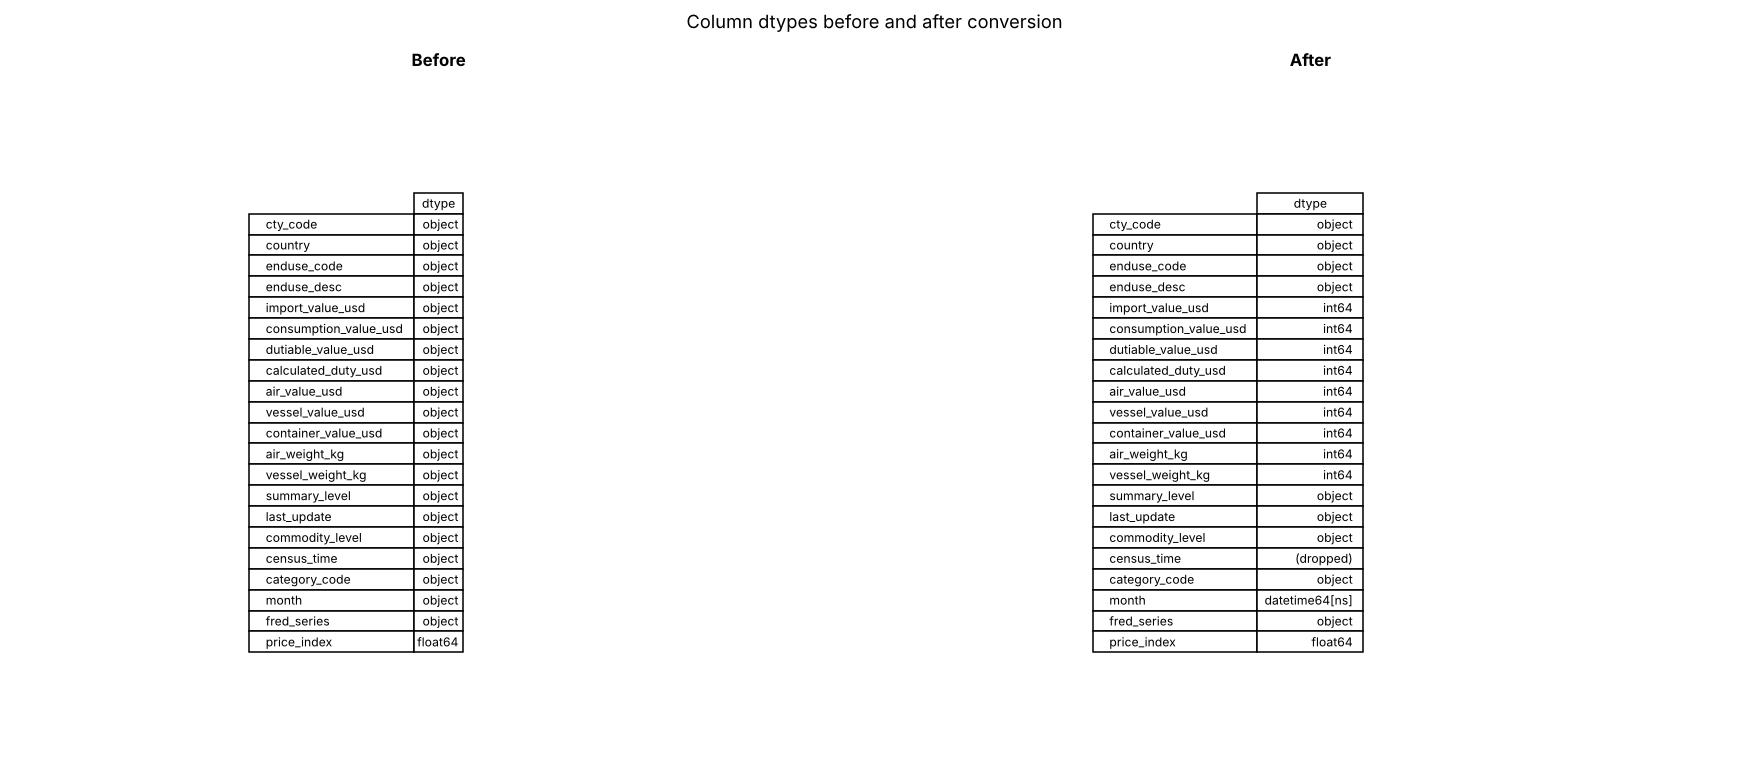

`errors="raise"` would have stopped the conversion on any non-numeric text; it ran cleanly, so every value cell was a valid integer.

In [11]:
LOG.append(dict(column="9 Census value and weight columns", problem="Numbers stored as text (object dtype)",
                action="pd.to_numeric to int64", before="dtype object; text max = " + str(df0["GEN_VAL_MO"].max()),
                after="dtype int64; max = " + f"{df['import_value_usd'].max():,}", member=MEMBER["part2"]))
LOG.append(dict(column="month", problem="Date stored as text YYYY-MM-01", action="pd.to_datetime; dropped duplicate text column census_time",
                before="dtype object", after="dtype datetime64", member=MEMBER["part2"]))

### 2.1.2 String normalization
`country` and `enduse_desc` are upper case. We strip whitespace and convert to title case. Code columns (`cty_code`, `enduse_code`, `summary_level`, `fred_series`) are identifiers and stay as they are.

In [12]:
STR_COLS = ["country", "enduse_desc"]
for c in STR_COLS:
    print(f"{c}: values with leading/trailing whitespace = {(df[c] != df[c].str.strip()).sum()}")

sample_idx = df.drop_duplicates("country").index[:8]
vc_before = {c: df[c].value_counts().head(6) for c in STR_COLS}
rows_before = df.loc[sample_idx, STR_COLS]

for c in STR_COLS:
    df[c] = df[c].str.strip().str.title()

before_after(rows_before, df.loc[sample_idx, STR_COLS], "Same rows, string columns before and after normalization", "g2_strings")
for c in STR_COLS:
    print(f"\n{c} value_counts BEFORE:\n{vc_before[c]}\n{c} value_counts AFTER:\n{df[c].value_counts().head(6)}")

country: values with leading/trailing whitespace = 0
enduse_desc: values with leading/trailing whitespace = 0


,country,enduse_desc
0,TOTAL FOR ALL COUNTRIES,"GENERATORS, ACCESSORIES"
1,EUROPEAN UNION,"GENERATORS, ACCESSORIES"
2,PACIFIC RIM COUNTRIES,"GENERATORS, ACCESSORIES"
3,CAFTA-DR,"GENERATORS, ACCESSORIES"
4,USMCA (NAFTA),"GENERATORS, ACCESSORIES"
5,TWENTY LATIN AMERICAN REPUBLICS,"GENERATORS, ACCESSORIES"
6,OECD,"GENERATORS, ACCESSORIES"
7,NATO,"GENERATORS, ACCESSORIES"
,country,enduse_desc
0,Total For All Countries,"Generators, Accessories"



country value_counts BEFORE:
country
TOTAL FOR ALL COUNTRIES    3795
APEC                       3795
OECD                       3795
NATO                       3794
EUROPE                     3793
NORTH AMERICA              3792
Name: count, dtype: int64
country value_counts AFTER:
country
Total For All Countries    3795
Apec                       3795
Oecd                       3795
Nato                       3794
Europe                     3793
North America              3792
Name: count, dtype: int64

enduse_desc value_counts BEFORE:
enduse_desc
ARTWORK, ANTIQUES, STAMPS, ETC.         10595
APPAREL, TEXTILES, NONWOOL OR COTTON    10376
ELECTRIC APPARATUS                      10132
INDUSTRIAL MACHINES, OTHER               9934
APPAREL, HOUSEHOLD GOODS - COTTON        9922
FURNITURE, HOUSEHOLD GOODS, ETC.         9825
Name: count, dtype: int64
enduse_desc value_counts AFTER:
enduse_desc
Artwork, Antiques, Stamps, Etc.         10595
Apparel, Textiles, Nonwool Or Cotton    10376
Electr

**Before / after evidence:**
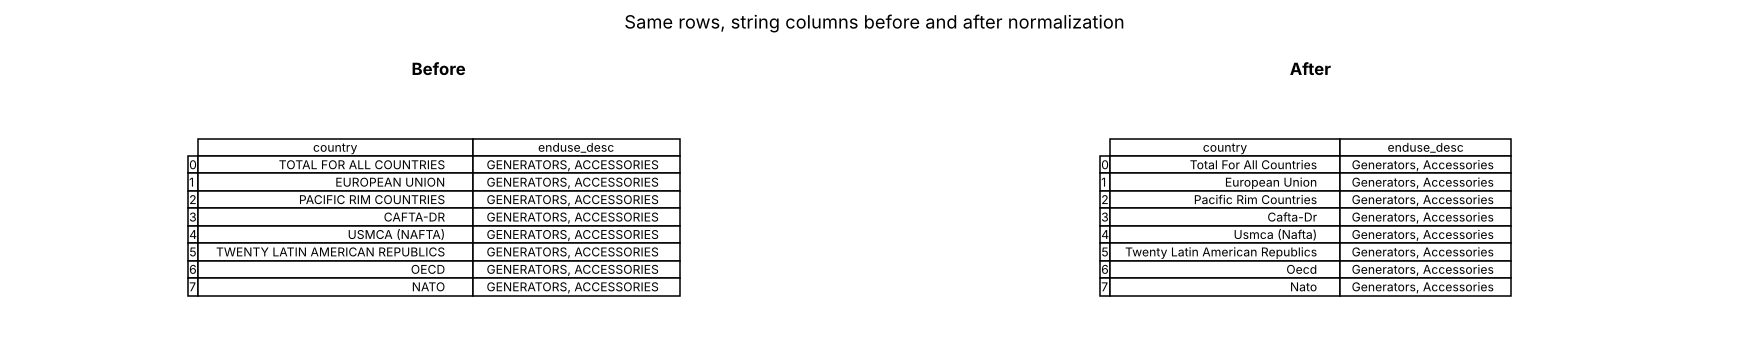

No values had stray whitespace (the API output is already trimmed), so `.str.strip()` changes nothing but guarantees it. Title case changes every value; the counts are identical before and after, which confirms no two different spellings were merged by accident.

In [13]:
for c in STR_COLS:
    LOG.append(dict(column=c, problem="Upper-case text, untrimmed", action=".str.strip().str.title()",
                    before="top: " + str(vc_before[c].index[0]), after="top: " + str(df[c].value_counts().index[0]),
                    member=MEMBER["part2"]))

### 2.1.3 Duplicate rows
One row should describe one partner, one end-use code, one month. We check full-row duplicates and duplicates on that key.

In [14]:
KEY = ["cty_code", "enduse_code", "month"]
dup_before = pd.DataFrame({"count": [len(df), df.duplicated().sum(), df.duplicated(KEY).sum()]},
                          index=["rows", "full-row duplicates", "duplicates on cty_code + enduse_code + month"])
df = df.drop_duplicates(KEY)
dup_after = pd.DataFrame({"count": [len(df), df.duplicated().sum(), df.duplicated(KEY).sum()]}, index=dup_before.index)
before_after(dup_before, dup_after, "Duplicate check (key = cty_code, enduse_code, month)", "g3_dups")

,count
rows,453105
full-row duplicates,0
duplicates on cty_code + enduse_code + month,0
,count
rows,453105
full-row duplicates,0
duplicates on cty_code + enduse_code + month,0


**Before / after evidence:**
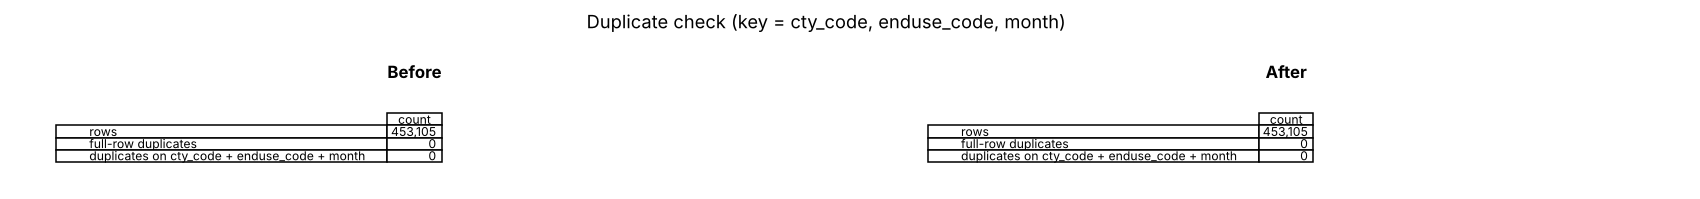

Duplicates were defined on `cty_code + enduse_code + month`. **Zero** duplicates were found: each API request covered one month, and the API returns each partner/code pair once. `drop_duplicates` is kept so the guarantee holds if the data is ever re-pulled.

In [15]:
LOG.append(dict(column="(all rows)", problem="Possible duplicate rows", action="drop_duplicates on cty_code + enduse_code + month",
                before=f"{int(dup_before.loc['duplicates on cty_code + enduse_code + month','count'])} duplicates",
                after="0 duplicates", member=MEMBER["part2"]))

## 2.2 Domain-specific problems

### Problem D1: a grand total row disguised as a detail row
The API includes `cty_code = "-"` (`Total For All Countries`) in every month and end-use code. It is labelled `summary_level = DET`, the same label as real countries, so filtering on `summary_level` alone does **not** remove it. Left in, it doubles every total we compute.

In [16]:
m = pd.Timestamp("2025-03-01")
det = df[df["summary_level"] == "DET"]
def d1_stat(frame):
    d = frame[(frame["summary_level"] == "DET") & (frame["month"] == m)]
    return pd.DataFrame({"value": [
        int((frame["cty_code"] == "-").sum()),
        round(d.loc[d["cty_code"] != "-", "import_value_usd"].sum() / 1e9, 2),
        round(d["import_value_usd"].sum() / 1e9, 2)]},
        index=["rows with cty_code '-'", "Mar 2025: sum over real countries (USD bn)", "Mar 2025: sum over all DET rows (USD bn)"])

stat_before = d1_stat(df)
official_totals = (df[df["cty_code"] == "-"].groupby("month")["import_value_usd"].sum().rename("official_total"))  # kept for D2 check
df = df[df["cty_code"] != "-"]
before_after(stat_before, d1_stat(df), "D1: grand-total row labelled as detail", "d1_total")

,value
rows with cty_code '-',"3,795"
Mar 2025: sum over real countries (USD bn),236.1900
Mar 2025: sum over all DET rows (USD bn),472.3800
,value
rows with cty_code '-',0.0000
Mar 2025: sum over real countries (USD bn),236.1900
Mar 2025: sum over all DET rows (USD bn),236.1900


**Before / after evidence:**
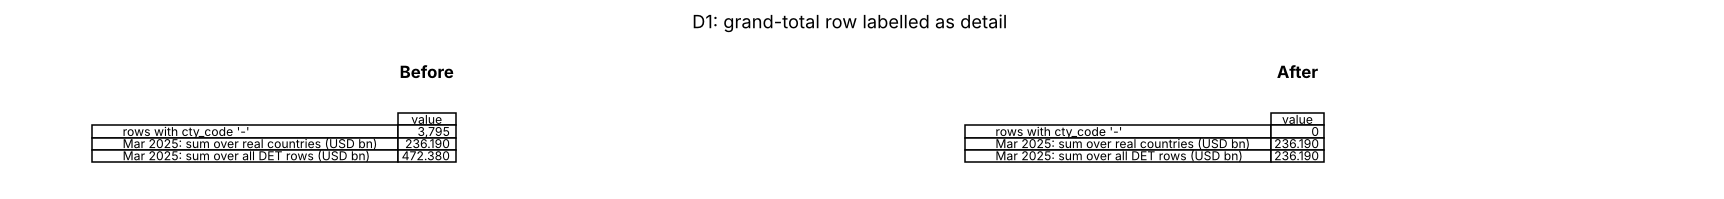

Before the fix, the "DET" sum for March 2025 is exactly twice the sum over real countries, because the total row repeats it. After removing the rows, the two match. We kept the official totals aside (`official_totals`) to check the next fix against Census's own number.

**Cross-check against D1:** the corrected March 2025 figure, $236.19bn, equals the sum of the three categories in the FT-900 Exhibit 13 file we used in D1 (93,464 + 43,040 + 99,686 = 236,190 million USD). Two independent Census products agree, so the cleaned data is counting the right trade.

In [17]:
LOG.append(dict(column="cty_code", problem="All-country total row labelled DET (double counts)", action="Dropped rows with cty_code '-'",
                before=f"{int(stat_before.iloc[0,0]):,} total rows; Mar 2025 DET sum ${stat_before.iloc[2,0]}bn",
                after=f"0 total rows; Mar 2025 DET sum ${stat_before.iloc[1,0]}bn", member=MEMBER["part2"]))

### Problem D2: country groupings mixed in with countries
Rows with `summary_level = CGP` are trade blocs and regions (European Union, OECD, NATO, USMCA, ASEAN, and continents such as `4XXX` Europe). A country like Germany appears in its own row **and** inside the EU, Euro Area, OECD, NATO and Europe rows, so any country-level analysis double or triple counts it.

In [18]:
cgp = df[df["summary_level"] == "CGP"]
print("Grouping rows found:", len(cgp))
print(cgp[["cty_code", "country"]].drop_duplicates().to_string(index=False))

def d2_stat(frame):
    by_month = frame.groupby("month")["import_value_usd"].sum()
    ratio = (by_month / official_totals).dropna()
    return pd.DataFrame({"value": [int((frame["summary_level"] == "CGP").sum()), frame["cty_code"].nunique(),
                                   round(ratio.min(), 3), round(ratio.max(), 3)]},
                        index=["CGP rows", "distinct partner codes", "min (sum of rows / official total)", "max (sum of rows / official total)"])

stat_before = d2_stat(df)
df = df[df["summary_level"] == "DET"]
before_after(stat_before, d2_stat(df), "D2: trade-bloc and region rows double counting countries", "d2_groups")

Grouping rows found: 70342
cty_code                         country
    0003                  European Union
    0014           Pacific Rim Countries
    0017                        Cafta-Dr
    0020                   Usmca (Nafta)
    0021 Twenty Latin American Republics
    0022                            Oecd
    0023                            Nato
    0024                           Lafta
    0025                       Euro Area
    0026                            Apec
    0027                           Asean
    0028                            Cacm
    1XXX                   North America
    2XXX                 Central America
    3XXX                   South America
    4XXX                          Europe
    5XXX                            Asia
    6XXX           Australia And Oceania
    7XXX                          Africa


,value
CGP rows,"70,342"
distinct partner codes,252.0000
min (sum of rows / official total),4.8560
max (sum of rows / official total),5.0950
,value
CGP rows,0.0000
distinct partner codes,233.0000
min (sum of rows / official total),1.0000
max (sum of rows / official total),1.0000


**Before / after evidence:**
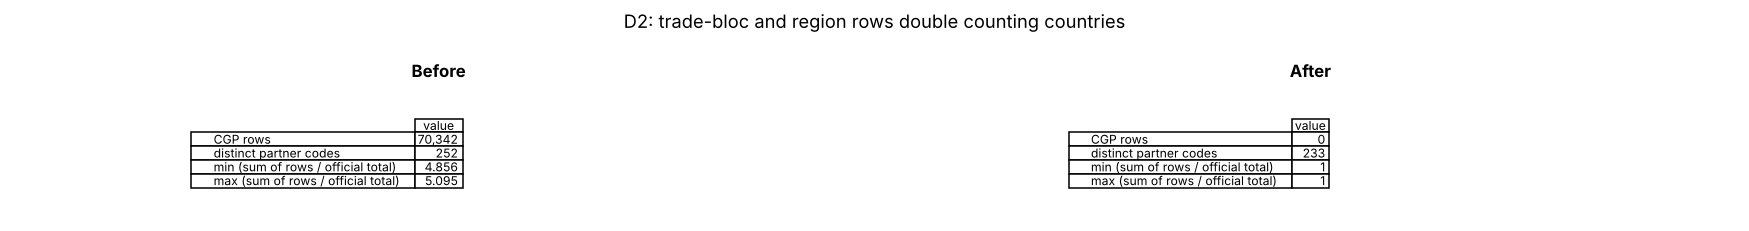

Before, summing all rows gives several times Census's official monthly total. After dropping the grouping rows, the sum of countries equals the official total in every one of the 55 months (ratio 1.000), so each import dollar is now counted exactly once.

In [19]:
LOG.append(dict(column="summary_level / cty_code", problem="Region and trade-bloc rows (CGP) double count countries",
                action="Kept DET rows only", before=f"{int(stat_before.iloc[0,0]):,} CGP rows; sum/official up to {stat_before.iloc[3,0]}x",
                after="0 CGP rows; sum/official = 1.000", member=MEMBER["part2"]))

### Problem D3: year-to-date "phantom" rows with no trade in the month
The number of rows per month climbs from January to December and then drops back every January (you can see it in the pull log). That happens because the API includes a partner/code pair if it traded **at any point so far that year**, even in months when it traded nothing. Those rows have **every** monthly measure equal to zero. Whether a zero row exists depends on earlier months, not on the month itself, so zeros are recorded inconsistently: a pair with no trade appears as 0 in December but is simply absent in January.

,rows in month,all-zero rows
2024-01,5009,0
2024-06,7162,2122
2024-12,8149,3104
2025-01,4974,0
2025-06,6861,1935
2025-12,7682,2652
,rows in month,all-zero rows
2024-01,5009,0
2024-06,5040,0
2024-12,5045,0


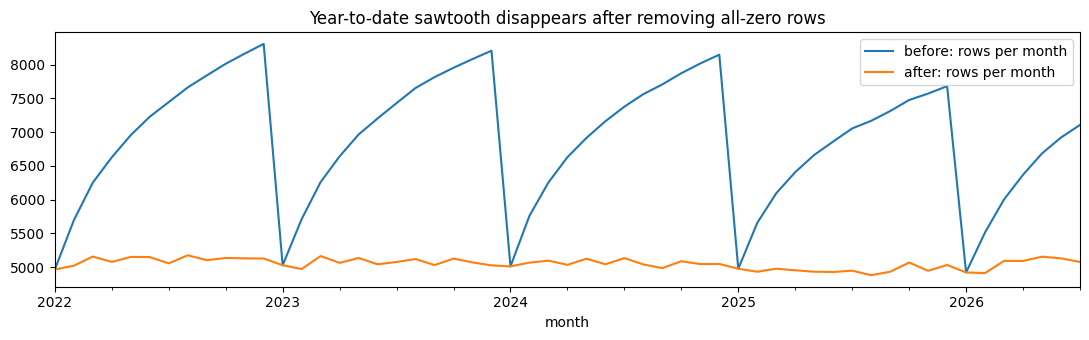

In [20]:
all_zero = df[VALUE_COLS].eq(0).all(axis=1)
show_months = pd.to_datetime(["2024-01-01", "2024-06-01", "2024-12-01", "2025-01-01", "2025-06-01", "2025-12-01"])
def d3_stat(frame):
    z = frame[VALUE_COLS].eq(0).all(axis=1)
    t = frame.groupby("month").size().reindex(show_months).to_frame("rows in month")
    t["all-zero rows"] = z.groupby(frame["month"]).sum().reindex(show_months)
    t.index = t.index.strftime("%Y-%m")
    return t

stat_before = d3_stat(df)
rows_month_before = df.groupby("month").size()
df = df[~all_zero]
before_after(stat_before, d3_stat(df), "D3: rows per month and all-zero rows", "d3_phantom")

fig, ax = plt.subplots(figsize=(11, 3.5))
rows_month_before.plot(ax=ax, label="before: rows per month")
df.groupby("month").size().plot(ax=ax, label="after: rows per month")
ax.set_title("Year-to-date sawtooth disappears after removing all-zero rows"); ax.legend(); plt.tight_layout(); plt.show()

**Before / after evidence:**
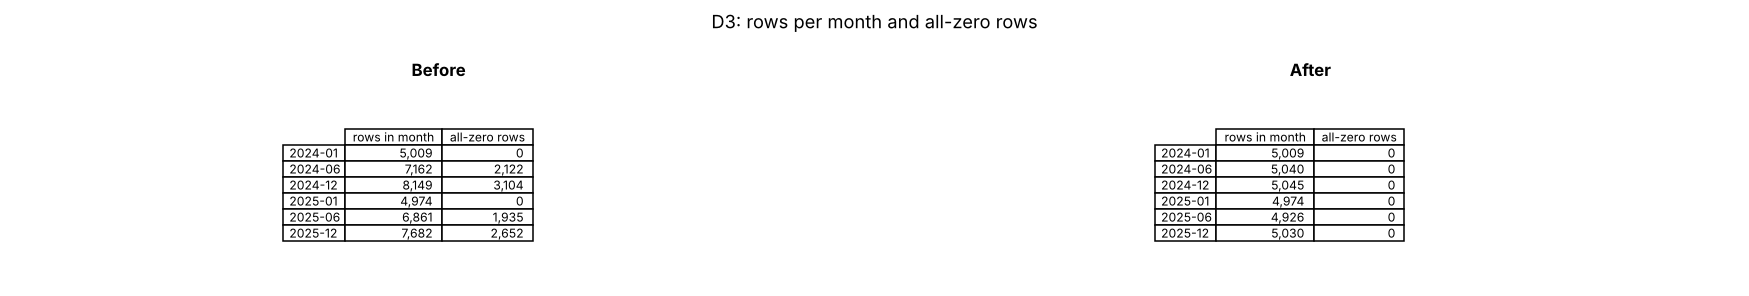

After removal, each month has a stable count of real trade flows and no all-zero rows. A partner/code pair that is absent in a month now consistently means "no trade that month". Rows with zero import value but some other non-zero measure (for example goods withdrawn from a bonded warehouse) are kept, because they record real activity.

In [21]:
LOG.append(dict(column="all value columns", problem="Year-to-date phantom rows: every monthly measure = 0",
                action="Dropped rows where all 9 measures are 0", before=f"{int(all_zero.sum()):,} all-zero rows",
                after="0 all-zero rows", member=MEMBER["part2"]))

### Problem D4: value shipped but weight recorded as 0 kg
A shipment that has a value by air or vessel must weigh something. Rows with a positive `air_value_usd` but `air_weight_kg = 0` (and the same for vessel) are not real zeros: Census records weight in whole kilograms, so very light shipments round down to 0. Treating that 0 as a measurement would make any value-per-kg calculation divide by zero. We convert these impossible zeros to `NaN`, so Part 3 can diagnose and impute them properly.

In [22]:
bad_air = (df["air_value_usd"] > 0) & (df["air_weight_kg"] == 0)
bad_ves = (df["vessel_value_usd"] > 0) & (df["vessel_weight_kg"] == 0)
cols = ["country", "enduse_desc", "month", "air_value_usd", "air_weight_kg", "vessel_value_usd", "vessel_weight_kg"]
idx = list(df[bad_air].index[:4]) + list(df[bad_ves].index[:3])
rows_before = df.loc[idx, cols].assign(month=lambda x: x["month"].dt.strftime("%Y-%m"))
print(f"air value > 0 with 0 kg: {bad_air.sum():,}   vessel value > 0 with 0 kg: {bad_ves.sum():,}")

df["air_weight_kg"] = df["air_weight_kg"].astype("float64").mask(bad_air)
df["vessel_weight_kg"] = df["vessel_weight_kg"].astype("float64").mask(bad_ves)
before_after(rows_before, df.loc[idx, cols].assign(month=lambda x: x["month"].dt.strftime("%Y-%m")),
             "D4: same rows, impossible 0 kg weights become NaN", "d4_weights")

air value > 0 with 0 kg: 2,521   vessel value > 0 with 0 kg: 113


,country,enduse_desc,month,air_value_usd,air_weight_kg,vessel_value_usd,vessel_weight_kg
4053,New Caledonia,Pharmaceutical Preparations,2022-01,2719,0,0,0
5688,Greenland,Numismatic Coins,2022-01,8306,0,0,0
5692,Guatemala,Numismatic Coins,2022-01,27000,0,0,0
5693,Haiti,Numismatic Coins,2022-01,3875,0,0,0
5707,Sweden,Numismatic Coins,2022-01,6579,0,2986,0
5710,United Kingdom,Numismatic Coins,2022-01,35695763,10532,21960,0
5714,France,Numismatic Coins,2022-01,1242775,21,22896,0
,country,enduse_desc,month,air_value_usd,air_weight_kg,vessel_value_usd,vessel_weight_kg
4053,New Caledonia,Pharmaceutical Preparations,2022-01,2719,NaN,0,0.0000
5688,Greenland,Numismatic Coins,2022-01,8306,NaN,0,0.0000


**Before / after evidence:**
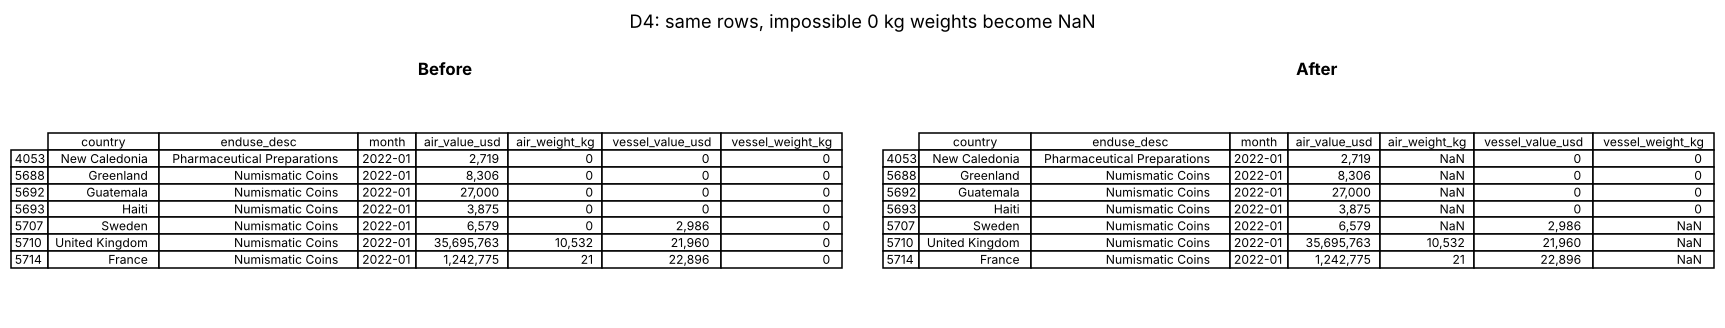

Rows where the value by that mode is also 0 keep their 0 kg, because "nothing shipped by air, 0 kg by air" is a true zero.

In [23]:
LOG.append(dict(column="air_weight_kg", problem="Air value > 0 but weight 0 kg (rounded below 1 kg)", action="Set to NaN (handled in Part 3)",
                before=f"{int(bad_air.sum()):,} impossible zeros", after=f"{int(df['air_weight_kg'].isna().sum()):,} NaN", member=MEMBER["part2"]))
LOG.append(dict(column="vessel_weight_kg", problem="Vessel value > 0 but weight 0 kg", action="Set to NaN (handled in Part 3)",
                before=f"{int(bad_ves.sum()):,} impossible zeros", after=f"{int(df['vessel_weight_kg'].isna().sum()):,} NaN", member=MEMBER["part2"]))

### Problem D5: Census-specific country names
Census uses its own naming conventions: inverted names (`Korea, South`), abbreviations (`St Lucia`), older names (`Burma`) and annotated names (`Falkland Islands (Islas Malvinas)`). These do not match the standard names other sources use (exchange rates, World Bank, UN data), so a later join on country name would silently fail for these partners. We map them to standard English short names. `cty_code` is unchanged, so no information is lost.

In [24]:
NAME_FIX = {
    "Korea, South": "South Korea", "Korea, North": "North Korea", "Burma": "Myanmar",
    "Falkland Islands (Islas Malvinas)": "Falkland Islands", "Svalbard, Jan Mayen Island": "Svalbard and Jan Mayen",
    "St Kitts And Nevis": "Saint Kitts And Nevis", "St Lucia": "Saint Lucia", "St Vincent And The Grenadines": "Saint Vincent And The Grenadines",
    "St Helena": "Saint Helena", "St Pierre And Miquelon": "Saint Pierre And Miquelon",
}
present = [n for n in NAME_FIX if n in set(df["country"])]
names_before = df[df["country"].isin(present)].groupby(["cty_code", "country"]).size().rename("rows").reset_index().set_index("cty_code")
df["country"] = df["country"].replace(NAME_FIX)
names_after = df[df["cty_code"].isin(names_before.index)].groupby(["cty_code", "country"]).size().rename("rows").reset_index().set_index("cty_code")
before_after(names_before, names_after.reindex(names_before.index), "D5: same partner codes, Census names vs standard names", "d5_names")

,country,rows
cty_code,,
1610,St Pierre And Miquelon,9
2483,St Kitts And Nevis,523
2487,St Lucia,234
2488,St Vincent And The Grenadines,119
3720,Falkland Islands (Islas Malvinas),33
4031,"Svalbard, Jan Mayen Island",15
5460,Burma,1391
5790,"Korea, North",1
5800,"Korea, South",3575


**Before / after evidence:**
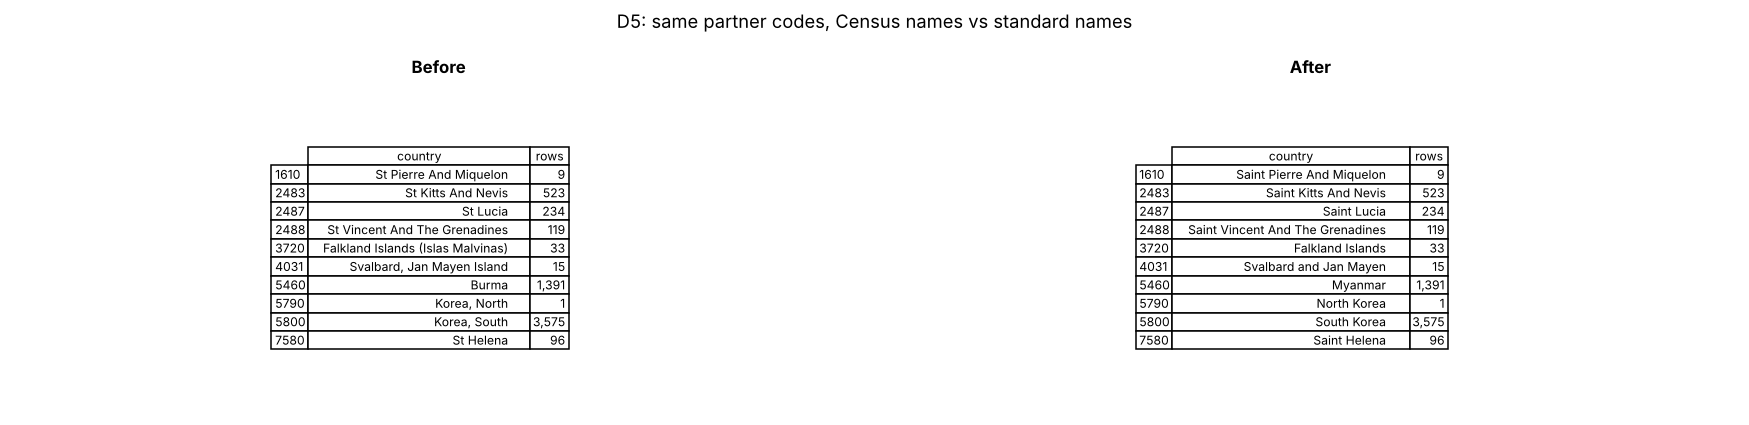

Same partner codes and same row counts; only the names changed.

In [25]:
LOG.append(dict(column="country", problem="Census-specific names (inverted, abbreviated, outdated)", action="Mapped 10 names to standard short names",
                before="e.g. 'Korea, South', 'Burma', 'St Lucia'", after="'South Korea', 'Myanmar', 'Saint Lucia'", member=MEMBER["part2"]))

### Problem D6: metadata columns with no information
`last_update` is `0` in every row (the API does not populate it at this level), `commodity_level` is always `EU5` (we requested 5 digit codes), and after D1 and D2 `summary_level` is always `DET`. A column with one value cannot explain anything and only adds noise, so we drop them.

In [26]:
META = ["last_update", "commodity_level", "summary_level"]
meta_before = pd.DataFrame({"unique values": df[META].nunique(), "example": df[META].iloc[0]})
df = df.drop(columns=META)
meta_after = pd.DataFrame({"unique values": ["(dropped)"] * 3, "example": ["(dropped)"] * 3}, index=META)
before_after(meta_before, meta_after, "D6: constant metadata columns", "d6_meta")

,unique values,example
last_update,1,0
commodity_level,1,EU5
summary_level,1,DET
,unique values,example
last_update,(dropped),(dropped)
commodity_level,(dropped),(dropped)
summary_level,(dropped),(dropped)


**Before / after evidence:**
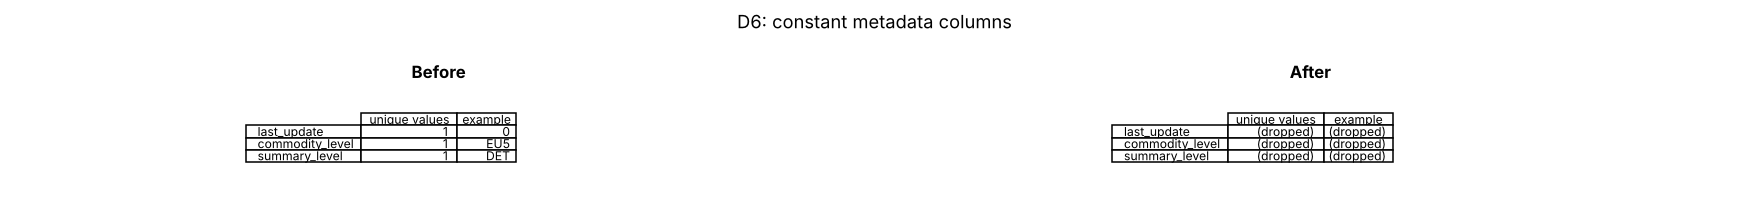

In [27]:
LOG.append(dict(column="last_update, commodity_level, summary_level", problem="Constant columns (1 unique value each)", action="Dropped",
                before="nunique = 1, 1, 1", after="columns removed", member=MEMBER["part2"]))
CATEGORY_NAME = {"2": "Capital goods", "3": "Automotive", "4": "Consumer goods"}
df["category"] = df["category_code"].map(CATEGORY_NAME)
df = df.reset_index(drop=True)
print("Dataset after Part 2:", df.shape)
df.head()

Dataset after Part 2: (277593, 18)


,cty_code,country,enduse_code,enduse_desc,import_value_usd,consumption_value_usd,dutiable_value_usd,calculated_duty_usd,air_value_usd,vessel_value_usd,container_value_usd,air_weight_kg,vessel_weight_kg,category_code,month,fred_series,price_index,category
0,1220,Canada,20000,"Generators, Accessories",107499386,107923317,6909147,270810,7705117,46471,46471,"27,729","3,029",2,2022-01-01,IR2,91.4000,Capital goods
1,2010,Mexico,20000,"Generators, Accessories",621390284,617165194,59181356,2013272,12922581,452706,452706,"226,874","56,175",2,2022-01-01,IR2,91.4000,Capital goods
2,2050,Guatemala,20000,"Generators, Accessories",109662,109662,0,0,109662,0,0,104.0000,0.0000,2,2022-01-01,IR2,91.4000,Capital goods
3,2150,Honduras,20000,"Generators, Accessories",149930,149930,149930,3702,149930,0,0,"6,056",0.0000,2,2022-01-01,IR2,91.4000,Capital goods
4,2230,Costa Rica,20000,"Generators, Accessories",1284680,1284680,221633,6741,1192746,54631,54631,"11,976",874.0000,2,2022-01-01,IR2,91.4000,Capital goods


**Part 2 summary.** Beyond the three general requirements, we found and fixed six structural problems specific to Census trade data: a mislabelled grand-total row (D1), overlapping trade-bloc and region rows (D2), year-to-date phantom rows (D3), impossible 0 kg weights (D4), non-standard country names (D5) and constant metadata columns (D6). D1 to D3 alone would have inflated every total several times over.

---
# Part 3: Missing Value Handling

In [28]:
miss = df.isna().sum()
miss = miss[miss > 0]
print(pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(2)}))

                  missing    pct
air_weight_kg        2521 0.9100
vessel_weight_kg      113 0.0400
price_index          5066 1.8200


## 3.1 Diagnosing the mechanism

### `price_index`
For each column we build a 0/1 missing indicator and compare it against other columns with `groupby`.

In [29]:
df["price_index_missing"] = df["price_index"].isnull().astype(int)

by_month = df.groupby(df["month"].dt.strftime("%Y-%m"))["price_index_missing"].mean()
print("Missing rate by month (only months above 0 shown):")
print(by_month[by_month > 0])
print("\nMissing rate by category:")
print(df.groupby("category")["price_index_missing"].mean())
print("\nMean import value by missing indicator:")
print(df.groupby("price_index_missing")["import_value_usd"].mean())

Missing rate by month (only months above 0 shown):
month
2025-10   1.0000
Name: price_index_missing, dtype: float64

Missing rate by category:
category
Automotive       0.0179
Capital goods    0.0178
Consumer goods   0.0187
Name: price_index_missing, dtype: float64

Mean import value by missing indicator:
price_index_missing
0   36,841,536
1   38,984,463
Name: import_value_usd, dtype: float64


**Reading the evidence.** The missing rate is **100% in October 2025 and 0% in every other month**, and it is identical across the three categories. So missingness is not random across rows (not MCAR): it depends entirely on an observed variable, `month`. Mean import value is similar for missing and non-missing rows, so the gap is not tied to trade size. It is tied to *when* BLS failed to publish, which lines up with the October 2025 federal government shutdown. The unobserved price itself does not cause it. Classification: **MAR** (missing because of the observed month).

### `air_weight_kg` and `vessel_weight_kg`

In [30]:
for w, v in [("air_weight_kg", "air_value_usd"), ("vessel_weight_kg", "vessel_value_usd")]:
    ind = w + "_missing"
    df[ind] = df[w].isnull().astype(int)
    shipped = df[df[v] > 0]                      # only rows that actually shipped by this mode
    print(f"\n=== {w} (rows with {v} > 0) ===")
    print(shipped.groupby(ind)[v].median().rename(f"median {v}"))
    print(shipped.groupby(ind)["import_value_usd"].median().rename("median import_value_usd"))
    print(shipped.groupby("category")[ind].mean().rename("missing rate by category"))


=== air_weight_kg (rows with air_value_usd > 0) ===
air_weight_kg_missing
0   169,575
1     7,196
Name: median air_value_usd, dtype: float64
air_weight_kg_missing
0   765,041
1     7,751
Name: median import_value_usd, dtype: float64
category
Automotive       0.0001
Capital goods    0.0001
Consumer goods   0.0202
Name: missing rate by category, dtype: float64

=== vessel_weight_kg (rows with vessel_value_usd > 0) ===
vessel_weight_kg_missing
0   608,190
1    10,171
Name: median vessel_value_usd, dtype: float64
vessel_weight_kg_missing
0    1,569,800
1   10,495,312
Name: median import_value_usd, dtype: float64
category
Automotive       0.0001
Capital goods    0.0000
Consumer goods   0.0012
Name: missing rate by category, dtype: float64


**Reading the evidence.** Among rows that shipped by air, the missing weights belong to shipments whose air value is **tiny** compared with normal shipments (see the medians above), and the rate also differs across categories. So the missingness is related to other columns and is not MCAR.

It is best explained by the **missing value itself**: Census reports weight in whole kilograms, so any air or vessel shipment that weighed less than 0.5 kg was recorded as 0 kg. The weight is missing *because* it is very small. That is the definition of **MNAR**. The link with low value is consistent with this (light shipments are usually cheap shipments), but the cause is the rounding of the unobserved weight, which we can argue from how Census records weight even though we cannot prove it from the data alone.

In [31]:
def evidence_price():
    return "Missing in 100% of Oct 2025 rows and 0% of other months, same rate in all 3 categories: depends on observed month."
rows = []
for col, cls, ev in [
    ("price_index", "MAR", evidence_price()),
    ("air_weight_kg", "MNAR", "Only on rows with tiny air shipments; weight rounds to 0 kg when under 0.5 kg, so the missing value itself causes the gap."),
    ("vessel_weight_kg", "MNAR", "Same rounding mechanism for vessel shipments under 0.5 kg; missing rows have far smaller vessel values."),
]:
    n = int(df[col].isna().sum())
    rows.append({"column": col, "missing count": n, "missing %": round(n / len(df) * 100, 3), "classification": cls, "evidence / reasoning": ev})
missing_summary = pd.DataFrame(rows).sort_values("missing %", ascending=False).reset_index(drop=True)
missing_summary

,column,missing count,missing %,classification,evidence / reasoning
0,price_index,5066,1.8250,MAR,Missing in 100% of Oct 2025 rows and 0% of oth...
1,air_weight_kg,2521,0.9080,MNAR,Only on rows with tiny air shipments; weight r...
2,vessel_weight_kg,113,0.0410,MNAR,Same rounding mechanism for vessel shipments u...


## 3.2 Imputation

### Most significant column: `price_index`, two techniques compared
* **Technique 1, group median:** fill with the median of that category's index over all months.
* **Technique 2, time interpolation:** fill each series' missing month by linear interpolation between September and November 2025 of the same series.

In [32]:
cat_median = df.groupby("fred_series")["price_index"].transform("median")
t1 = df["price_index"].fillna(cat_median)

series = (fred.assign(month=pd.to_datetime(fred["observation_date"]))
              .sort_values(["fred_series", "month"]))
series["price_interp"] = series.groupby("fred_series")["price_index"].transform(lambda s: s.interpolate(method="linear"))
interp_map = series.set_index(["fred_series", "month"])["price_interp"]
t2 = df["price_index"].fillna(pd.Series(interp_map.reindex(pd.MultiIndex.from_frame(df[["fred_series", "month"]])).values, index=df.index))

check = series[series["month"].between("2025-09-01", "2025-11-01")].pivot(index="month", columns="fred_series", values="price_index")
check.loc["Oct imputed, technique 1 (median)"] = df.groupby("fred_series")["price_index"].median()
check.loc["Oct imputed, technique 2 (interpolation)"] = series[series["month"] == "2025-10-01"].set_index("fred_series")["price_interp"]
check

fred_series,IR2,IR3,IR4
month,,,
2025-09-01 00:00:00,94.9000,120.3000,110.1000
2025-10-01 00:00:00,NaN,NaN,NaN
2025-11-01 00:00:00,95.1000,120.0000,110.2000
"Oct imputed, technique 1 (median)",93.6000,120.0000,110.2000
"Oct imputed, technique 2 (interpolation)",95.0000,120.1500,110.1500


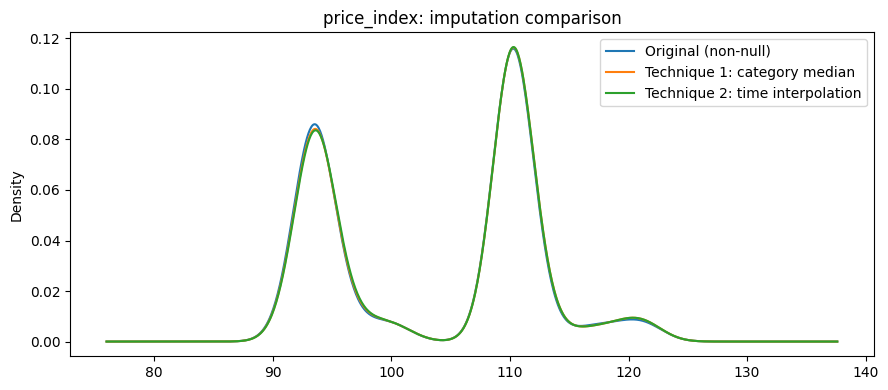

In [33]:
sample_orig = df["price_index"].dropna().sample(min(5000, len(df)), random_state=42)
sample_t1 = t1.sample(min(5000, len(df)), random_state=42)
sample_t2 = t2.sample(min(5000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 4))
sample_orig.plot(kind="kde", ax=ax, label="Original (non-null)")
sample_t1.plot(kind="kde", ax=ax, label="Technique 1: category median")
sample_t2.plot(kind="kde", ax=ax, label="Technique 2: time interpolation")
ax.legend(); ax.set_title("price_index: imputation comparison"); plt.tight_layout(); plt.show()

**Which technique we kept: time interpolation.** Our diagnosis says the gap is MAR on `month`: one month is missing from three otherwise continuous monthly series. The best estimate of a missing month in a slow-moving price index is its own neighbours, and interpolation uses exactly that. The category median ignores time: it fills October 2025 with a value from the middle of a 4.5 year window. For IR2 that gives 93.6, below both real neighbours (94.9 in September, 95.1 in November), so every capital-goods row in October would get a price level that never happened. Interpolation gives 95.0, between its neighbours. Both curves look almost identical to the original because only about 2% of rows were missing, but the table shows interpolation is the one that is actually right for each row.

In [34]:
pi_missing_before = int(df["price_index"].isna().sum())
df["price_index"] = t2
LOG.append(dict(column="price_index", problem="Blank FRED value for Oct 2025 (MAR on month)", action="Linear interpolation within each series",
                before=f"{pi_missing_before:,} missing", after=f"{int(df['price_index'].isna().sum())} missing", member=MEMBER["part3"]))

### Remaining columns: `air_weight_kg` and `vessel_weight_kg` (MNAR)
Following the MNAR rule, we keep a NaN indicator column (already created above: `air_weight_kg_missing`, `vessel_weight_kg_missing`) and then fill with an **end-of-distribution** value. Because the true weight is known to be below 0.5 kg (it rounded to 0), we use **0.5 kg**, the top of that interval and the bottom end of the observed distribution (the smallest recorded weight is 1 kg). The indicator keeps the information that the weight was never measured.

In [35]:
WCOLS = ["air_weight_kg", "vessel_weight_kg"]
w_before = pd.DataFrame({"missing": df[WCOLS].isna().sum(), "smallest positive weight": df[WCOLS][df[WCOLS] > 0].min()})
for w in ["air_weight_kg", "vessel_weight_kg"]:
    n = int(df[w].isna().sum())
    df[w] = df[w].fillna(0.5)
    LOG.append(dict(column=w, problem="Weight under 0.5 kg recorded as 0 (MNAR)", action="NaN indicator column + fill 0.5 kg",
                    before=f"{n:,} missing", after="0 missing; indicator kept", member=MEMBER["part3"]))
w_after = pd.DataFrame({"missing": df[WCOLS].isna().sum(), "smallest positive weight": df[WCOLS][df[WCOLS] > 0].min()})
pd.concat({"before": w_before, "after": w_after}, axis=1)

before                            after                         
                 missing smallest positive weight missing smallest positive weight
air_weight_kg       2521                   1.0000       0                   0.5000
vessel_weight_kg     113                   1.0000       0                   0.5000

In [36]:
df.isnull().sum()

cty_code                    0
country                     0
enduse_code                 0
enduse_desc                 0
import_value_usd            0
consumption_value_usd       0
dutiable_value_usd          0
calculated_duty_usd         0
air_value_usd               0
vessel_value_usd            0
container_value_usd         0
air_weight_kg               0
vessel_weight_kg            0
category_code               0
month                       0
fred_series                 0
price_index                 0
category                    0
price_index_missing         0
air_weight_kg_missing       0
vessel_weight_kg_missing    0
dtype: int64

Every column now returns 0 missing values. No column was dropped.

---
# Part 4: Outlier Handling

## 4.1 Detection with the 1.5 x IQR rule

In [37]:
NUM_COLS = VALUE_COLS + ["price_index"]
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"column": c, "Q1": q1, "Q3": q3, "IQR": iqr, "lower": lo, "upper": hi, "outliers": n, "% flagged": round(n / len(df) * 100, 2)})
iqr_table = pd.DataFrame(rows).set_index("column")
iqr_table

,Q1,Q3,IQR,lower,upper,outliers,% flagged
column,,,,,,,
import_value_usd,"33,674","5,713,348","5,679,674","-8,485,837","14,232,859",48271,17.3900
consumption_value_usd,"33,417","5,663,055","5,629,638","-8,411,040","14,107,512",48340,17.4100
dutiable_value_usd,0.0000,"1,060,725","1,060,725","-1,591,088","2,651,812",50540,18.2100
calculated_duty_usd,0.0000,"75,362","75,362","-113,043","188,405",51883,18.6900
air_value_usd,"6,111","1,042,177","1,036,066","-1,547,988","2,596,276",48723,17.5500
vessel_value_usd,0.0000,"1,874,998","1,874,998","-2,812,497","4,687,495",50000,18.0100
container_value_usd,0.0000,"1,656,003","1,656,003","-2,484,004","4,140,008",49679,17.9000
air_weight_kg,35.0000,"13,025","12,990","-19,450","32,510",46845,16.8800
vessel_weight_kg,0.0000,"130,327","130,327","-195,490","325,818",50782,18.2900


Trade values are extremely right-skewed (a handful of partners such as Mexico and China ship billions a month while most pairs ship thousands), so the IQR rule flags a large share of rows in every value column. That is why the handling below is decided per column from what the column means, not applied blindly.

## 4.2 Handling

In [38]:
# DROP: calculated_duty_usd rows where duty exceeds the value of the goods before 2025
impossible = (df["calculated_duty_usd"] > df["consumption_value_usd"]) & (df["month"] < "2025-01-01")
later = (df["calculated_duty_usd"] > df["consumption_value_usd"]) & (df["month"] >= "2025-01-01")
cols = ["country", "enduse_desc", "month", "consumption_value_usd", "calculated_duty_usd"]
print(f"Duty > value before 2025: {impossible.sum()} row(s).   Duty > value in 2025-2026: {later.sum()} rows (kept).")
drop_before = df.loc[impossible, cols].assign(month=lambda x: x["month"].dt.strftime("%Y-%m"))
n_before = len(df)
df = df[~impossible].reset_index(drop=True)
drop_after = pd.DataFrame({"rows matching the rule": [int(((df["calculated_duty_usd"] > df["consumption_value_usd"]) & (df["month"] < "2025-01-01")).sum())],
                           "dataset rows": [len(df)]})
display(drop_before); display(drop_after)
print("Examples of 2025-2026 rows kept (real tariff stacking):")
df.loc[(df["calculated_duty_usd"] > df["consumption_value_usd"]), cols].sort_values("consumption_value_usd", ascending=False).head(4)

Duty > value before 2025: 1 row(s).   Duty > value in 2025-2026: 31 rows (kept).


,country,enduse_desc,month,consumption_value_usd,calculated_duty_usd
150905,Kenya,Other Consumer Nondurables,2024-06,5462,19118


,rows matching the rule,dataset rows
0,0,277592


Examples of 2025-2026 rows kept (real tariff stacking):


,country,enduse_desc,month,consumption_value_usd,calculated_duty_usd
204746,China,"Passenger Cars, New And Used",2025-05-01,59854722,68527599
274217,Luxembourg,Laboratory Testing Instruments,2026-07-01,264344,441592
200317,Hong Kong,"Apparel, Household Goods - Wool",2025-04-01,161609,175679
240952,Slovenia,"Cookware, Cutlery, Tools",2025-12-01,70218,74475


**`calculated_duty_usd`: drop (1 row).** This column is the tariff actually owed. Before 2025, no tariff in force on these goods came close to 100% of their value, so a 2024 row where duty is 3.5 times the value of a small shipment is almost certainly an entry error, and a single $5,000 shipment adds nothing to our analysis of tariff policy. In 2025 and 2026, duty above value is **genuine**: stacked tariffs (for example the 2025 tariffs on Chinese goods, including passenger cars above) did exceed 100%, and those rows are exactly the phenomenon we study. They stay, and the rest of this column's IQR outliers stay unchanged, because large duties are the tariff signal itself.

In [39]:
LOG.append(dict(column="calculated_duty_usd", problem="Duty > goods value before 2025 (entry error)", action="Dropped row; 2025-26 cases kept as real",
                before=f"{int(impossible.sum())} impossible row(s); {n_before:,} rows", after=f"0 impossible rows; {len(df):,} rows", member=MEMBER["part4"]))

# FLAG: import_value_usd
q1, q3 = df["import_value_usd"].quantile([0.25, 0.75]); upper_imp = q3 + 1.5 * (q3 - q1)
df["is_outlier_import_value"] = (df["import_value_usd"] > upper_imp).astype(int)
print(f"import_value_usd upper bound: ${upper_imp:,.0f}; flagged rows: {df['is_outlier_import_value'].sum():,} ({df['is_outlier_import_value'].mean():.1%})")
print("Flagged share by partner (top 8):")
df[df["is_outlier_import_value"] == 1]["country"].value_counts().head(8)

import_value_usd upper bound: $14,232,970; flagged rows: 48,270 (17.4%)
Flagged share by partner (top 8):


country
China      3027
Mexico     2811
Canada     2536
Germany    2328
Italy      2250
Japan      2202
India      1892
Vietnam    1873
Name: count, dtype: int64

**`import_value_usd`: flag.** This is our target. Its extreme values are not errors; they are the largest real trade relationships (Mexico, China, Canada, Germany and the like), and they are where a tariff shock moves the most dollars. Removing or capping them would delete the most important observations, so we keep every value unchanged and add `is_outlier_import_value`, which tells later models which rows are the major flows.

In [40]:
LOG.append(dict(column="import_value_usd", problem="Very large flows (IQR outliers)", action="Flag column is_outlier_import_value; values unchanged",
                before=f"max ${df['import_value_usd'].max():,.0f}", after=f"max unchanged; {int(df['is_outlier_import_value'].sum()):,} rows flagged", member=MEMBER["part4"]))

# CAP: shipping weights
cap_rows = []
for w in ["air_weight_kg", "vessel_weight_kg"]:
    hi = iqr_table.loc[w, "upper"]
    n = int((df[w] > hi).sum())
    cap_rows.append({"column": w, "upper bound (kg)": round(hi, 1), "rows capped": n, "max before": df[w].max()})
    df[w] = df[w].clip(upper=hi)
    cap_rows[-1]["max after"] = df[w].max()
    LOG.append(dict(column=w, problem="Extreme bulk shipping weights", action=f"Capped at IQR upper bound {hi:,.0f} kg",
                    before=f"max {cap_rows[-1]['max before']:,.0f} kg", after=f"max {hi:,.0f} kg ({n:,} rows capped)", member=MEMBER["part4"]))
pd.DataFrame(cap_rows).set_index("column")

,upper bound (kg),rows capped,max before,max after
column,,,,
air_weight_kg,"32,510",46845,"36,887,199","32,510"
vessel_weight_kg,"325,818",50782,"556,279,814","325,818"


**`air_weight_kg` and `vessel_weight_kg`: cap.** These are shipping weights in kg. The extremes are plausible (bulk cargoes run to hundreds of millions of kg), not errors, so the rows stay: their values and tariffs matter. But a single 556 million kg cargo would dominate any weight-based average or model input, so we cap each weight at its IQR upper bound. Because the distribution is so skewed, the cap touches about 17% of rows; we accept that because weight is a secondary measure for our question (it is not the target and no feature in Part 6 depends on it), and the rank order below the cap is untouched.

**`consumption_value_usd`, `dutiable_value_usd`, `air_value_usd`, `vessel_value_usd`, `container_value_usd`: no action.** These are components of the same import dollars that `import_value_usd` measures, and their outliers are the same large partner flows already marked by `is_outlier_import_value`. Capping them separately would break the accounting identities in the data (for example air value plus vessel value can never exceed import value) and would distort the tariff rate we compute from consumption value in Part 6.

**`price_index`:** the IQR table shows no outliers. The three indexes move within a narrow range, so no handling is needed.

---
# Part 5: Scaling and Transformation

## 5.1 Skewness audit

In [41]:
SKEW_COLS = NUM_COLS
sk = df[SKEW_COLS].skew()
def decide(c, s):
    if abs(s) > 1:
        return "transform", "Significant right skew from a few very large flows; a log or sqrt transform is needed before scaling."
    if abs(s) >= 0.5:
        return "transform", "Moderate skew; a transform may help."
    return "scale only", "Approximately symmetric; no transform needed, only scaling."
skew_table = pd.DataFrame([{"column": c, "skewness": round(s, 3), "decision": decide(c, s)[0], "reason": decide(c, s)[1]}
                           for c, s in sk.items()])
skew_table = skew_table.reindex(skew_table["skewness"].abs().sort_values(ascending=False).index).reset_index(drop=True)
skew_table

,column,skewness,decision,reason
0,air_value_usd,51.9590,transform,Significant right skew from a few very large f...
1,import_value_usd,24.6990,transform,Significant right skew from a few very large f...
2,consumption_value_usd,23.8740,transform,Significant right skew from a few very large f...
3,calculated_duty_usd,22.9890,transform,Significant right skew from a few very large f...
4,dutiable_value_usd,20.1840,transform,Significant right skew from a few very large f...
5,vessel_value_usd,18.7870,transform,Significant right skew from a few very large f...
6,container_value_usd,17.1780,transform,Significant right skew from a few very large f...
7,air_weight_kg,1.2020,transform,Significant right skew from a few very large f...
8,vessel_weight_kg,1.1920,transform,Significant right skew from a few very large f...
9,price_index,-0.0810,scale only,"Approximately symmetric; no transform needed, ..."


## 5.2 Transformation
For every column marked `transform`, we compare log(x + 1) and square root on a 5,000 row sample and keep the version with the lower absolute skewness.

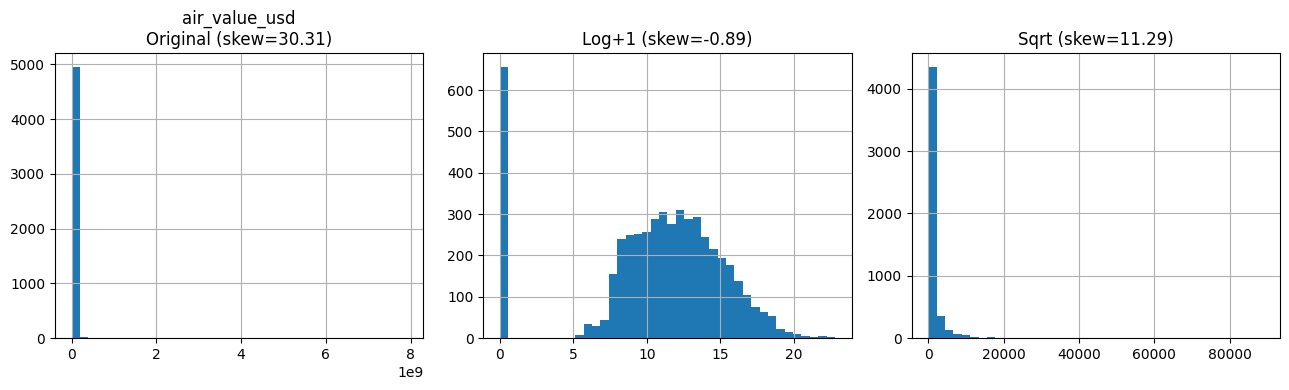

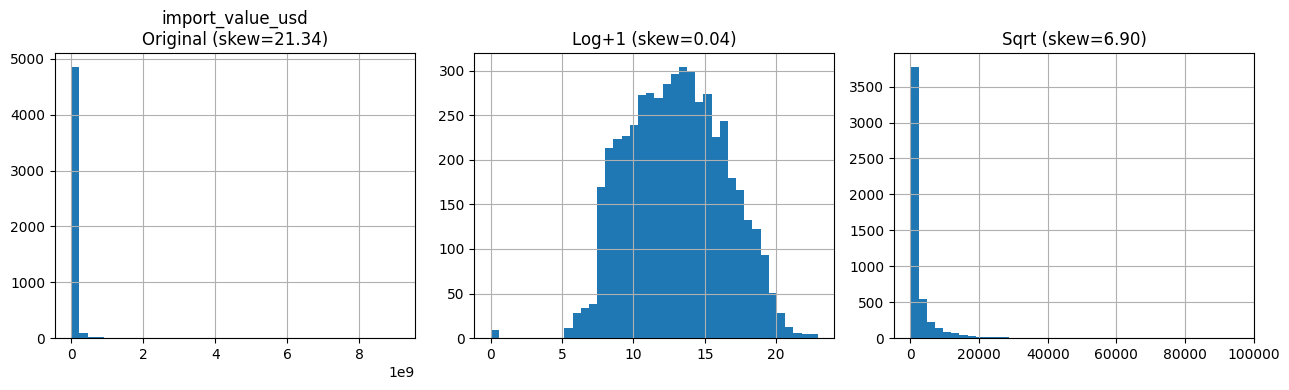

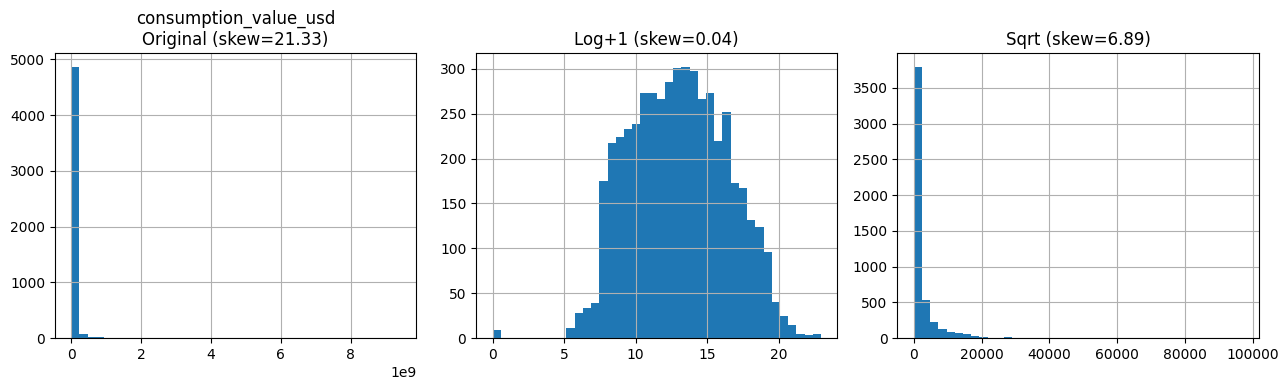

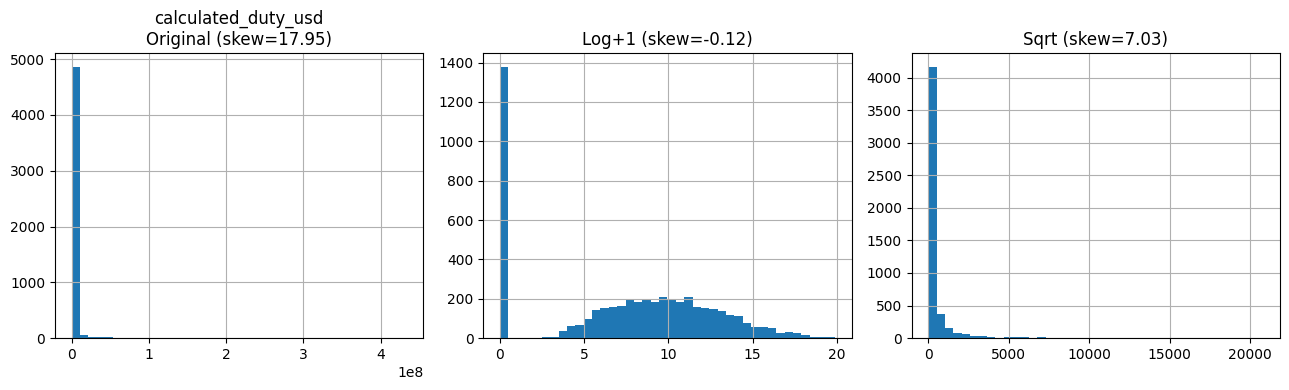

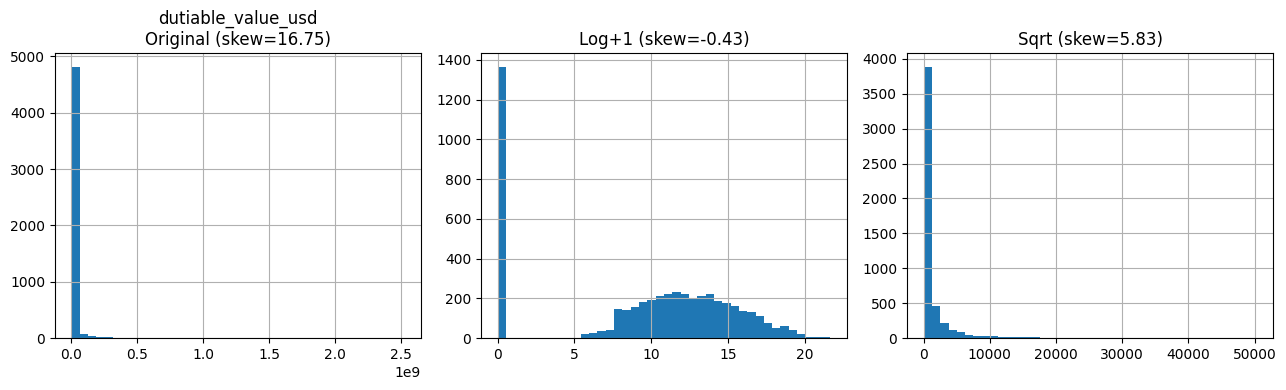

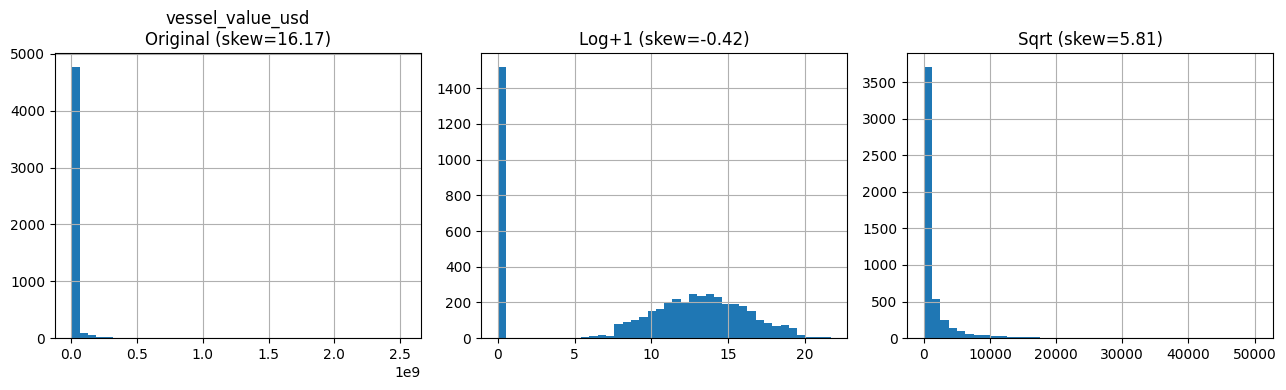

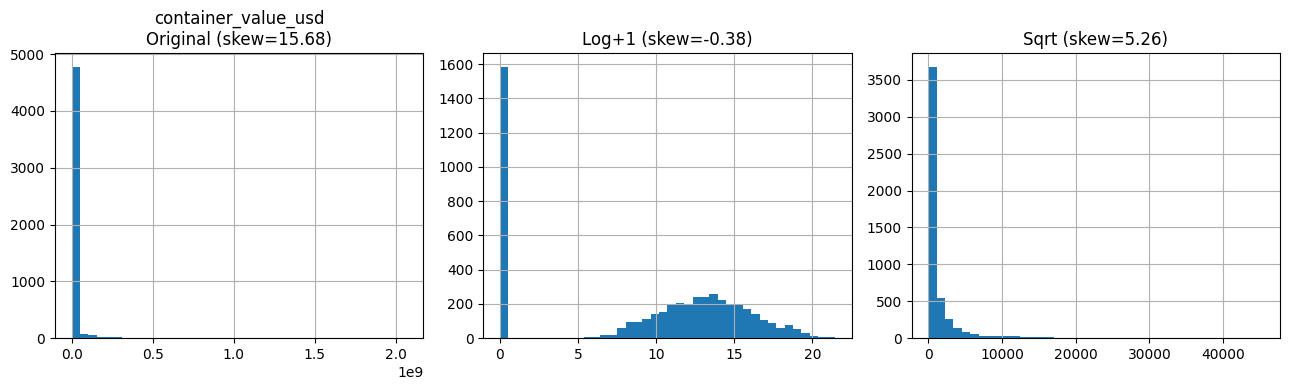

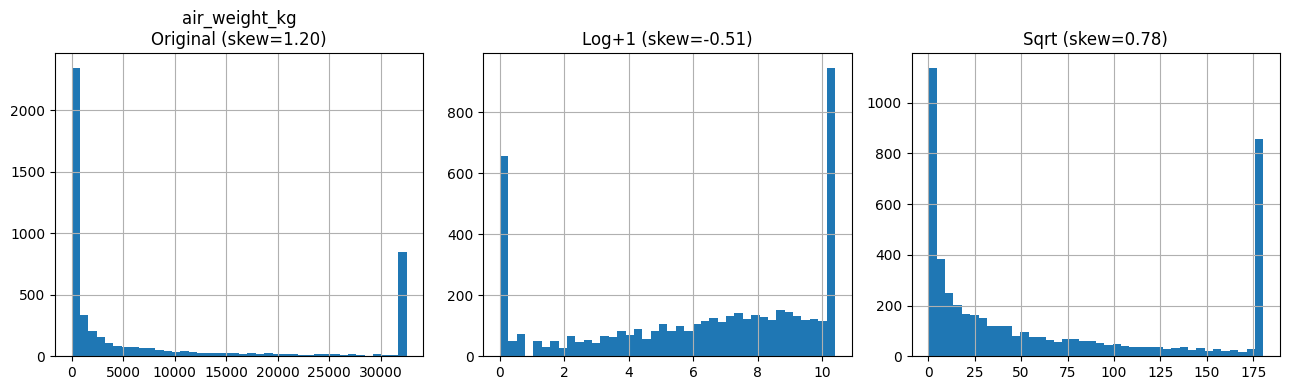

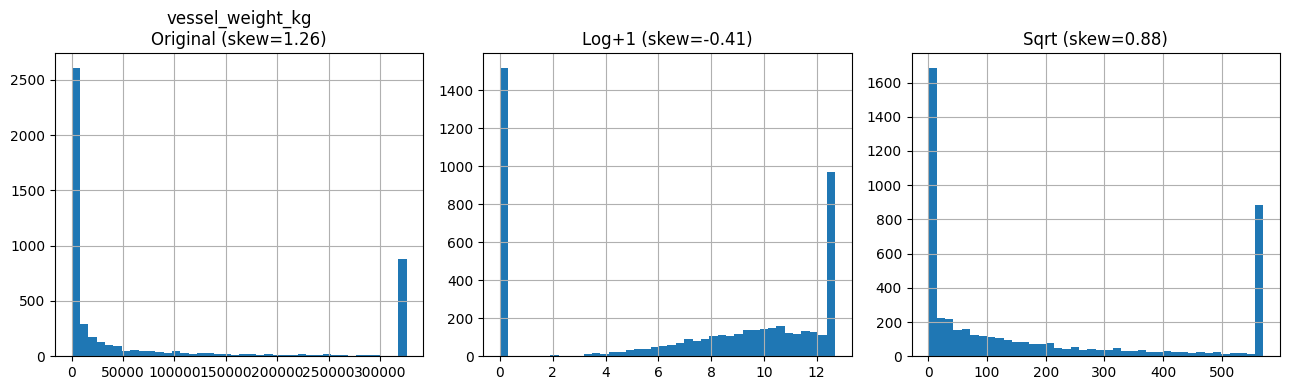

,skew original,skew log+1,skew sqrt,kept,new column
column,,,,,
air_value_usd,51.9590,-0.8770,9.7300,log,air_value_usd_log
import_value_usd,24.6990,-0.0100,5.9690,log,import_value_usd_log
consumption_value_usd,23.8740,-0.0390,5.9600,log,consumption_value_usd_log
calculated_duty_usd,22.9890,-0.1200,8.2460,log,calculated_duty_usd_log
dutiable_value_usd,20.1840,-0.4230,6.6040,log,dutiable_value_usd_log
vessel_value_usd,18.7870,-0.4140,5.8770,log,vessel_value_usd_log
container_value_usd,17.1780,-0.3740,5.3320,log,container_value_usd_log
air_weight_kg,1.2020,-0.5110,0.7920,log,air_weight_kg_log
vessel_weight_kg,1.1920,-0.3890,0.8340,log,vessel_weight_kg_log


In [42]:
transform_results = []
for c in skew_table.loc[skew_table["decision"] == "transform", "column"]:
    sample = df[c].sample(min(5000, len(df)), random_state=42)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    sample.hist(bins=40, ax=axes[0])
    np.log(sample + 1).hist(bins=40, ax=axes[1])
    np.sqrt(sample).hist(bins=40, ax=axes[2])
    axes[0].set_title(f"{c}\nOriginal (skew={sample.skew():.2f})")
    axes[1].set_title(f"Log+1 (skew={np.log(sample + 1).skew():.2f})")
    axes[2].set_title(f"Sqrt (skew={np.sqrt(sample).skew():.2f})")
    plt.tight_layout(); plt.show()

    full_log, full_sqrt = np.log(df[c] + 1), np.sqrt(df[c])
    best = "log" if abs(full_log.skew()) <= abs(full_sqrt.skew()) else "sqrt"
    new = f"{c}_{best}"
    df[new] = full_log if best == "log" else full_sqrt
    transform_results.append({"column": c, "skew original": round(df[c].skew(), 3), "skew log+1": round(full_log.skew(), 3),
                              "skew sqrt": round(full_sqrt.skew(), 3), "kept": best, "new column": new})
    LOG.append(dict(column=c, problem=f"Skewness {df[c].skew():.2f}", action=f"Kept {best} transform as {new}",
                    before=f"skew {df[c].skew():.2f}", after=f"skew {df[new].skew():.2f}", member=MEMBER["part5"]))
transform_results = pd.DataFrame(transform_results).set_index("column")
transform_results

**Result.** For every value and weight column, **log(x + 1) gives the lower absolute skewness**, so we keep the log versions (new `_log` columns; the original dollar columns stay for interpretation). The square root reduces skew but cannot handle a range that spans from a few hundred dollars to tens of billions; the log turns that multiplicative range into an additive one, which matches how trade flows grow (in percentages, not fixed amounts).

## 5.3 Scaling

**Choice: Robust Scaling for the log value columns, Z-score for `price_index`.**

In Part 4 we **kept** the large import flows and marked them with `is_outlier_import_value` instead of removing or capping them. Robust scaling uses the **median** and **IQR** as its centre and spread. Neither statistic moves when the largest flows grow, whereas the mean and standard deviation are pulled toward exactly the outliers we chose to keep. So robust scaling keeps the typical rows on a comparable scale without letting Mexico and China set the scale for everyone.

`price_index` has no outliers (Part 4) and is roughly symmetric (Part 5.1), so plain Z-score standardization is appropriate there: the output has mean 0 and standard deviation 1, which puts the index on the same footing as other standardized inputs.

In [43]:
LOG_VALUE_COLS = [c for c in transform_results["new column"] if c.endswith("_log") and "weight" not in c]
for c in LOG_VALUE_COLS:
    med, iqr = df[c].median(), df[c].quantile(0.75) - df[c].quantile(0.25)
    df[c + "_robust"] = (df[c] - med) / iqr
mu, sd = df["price_index"].mean(), df["price_index"].std()
df["price_index_z"] = (df["price_index"] - mu) / sd

scaled = [c + "_robust" for c in LOG_VALUE_COLS] + ["price_index_z"]
print("Robust-scaled columns: median should be 0 and IQR 1.  Z-score: mean 0, std 1.")
desc = df[scaled].describe().T
desc["IQR"] = df[scaled].quantile(0.75) - df[scaled].quantile(0.25)
desc

Robust-scaled columns: median should be 0 and IQR 1.  Z-score: mean 0, std 1.


,count,mean,std,min,25%,50%,75%,max,IQR
air_value_usd_log_robust,"277,592",-0.1571,0.9665,-2.2134,-0.5169,0.0000,0.4831,2.4612,1.0000
import_value_usd_log_robust,"277,592",0.0039,0.6634,-2.5366,-0.5060,0.0000,0.4940,2.1509,1.0000
consumption_value_usd_log_robust,"277,592",0.0026,0.6663,-2.5360,-0.5065,0.0000,0.4935,2.1340,1.0000
calculated_duty_usd_log_robust,"277,592",-0.0734,0.4672,-0.7144,-0.7144,0.0000,0.2856,1.1489,1.0000
dutiable_value_usd_log_robust,"277,592",-0.1164,0.4465,-0.7742,-0.7742,0.0000,0.2258,0.8336,1.0000
vessel_value_usd_log_robust,"277,592",-0.1538,0.4572,-0.7936,-0.7936,0.0000,0.2064,0.7390,1.0000
container_value_usd_log_robust,"277,592",-0.1609,0.4631,-0.7912,-0.7912,-0.0000,0.2088,0.7511,1.0000
price_index_z,"277,592",-0.0000,1.0000,-1.4114,-1.1540,0.6473,0.7256,2.0346,1.8796


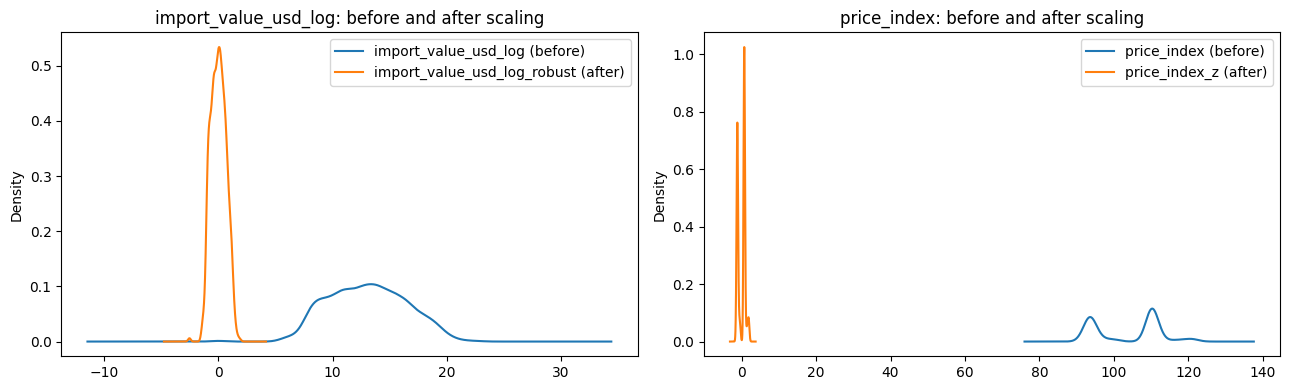

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (raw, sc) in zip(axes, [("import_value_usd_log", "import_value_usd_log_robust"), ("price_index", "price_index_z")]):
    df[raw].sample(min(5000, len(df)), random_state=42).plot(kind="kde", ax=ax, label=f"{raw} (before)")
    df[sc].sample(min(5000, len(df)), random_state=42).plot(kind="kde", ax=ax, label=f"{sc} (after)")
    ax.legend(); ax.set_title(f"{raw}: before and after scaling")
plt.tight_layout(); plt.show()

The robust-scaled columns are centred on a median of 0 with an IQR of 1, and `price_index_z` has mean about 0 and standard deviation 1. The KDE plots show the shape is preserved; only the location and spread change.

In [45]:
LOG.append(dict(column="*_log value columns", problem="Different scales, outliers kept", action="Robust scaling (median, IQR) to *_robust",
                before=f"import_value_usd_log median {df['import_value_usd_log'].median():.2f}", after="median 0, IQR 1", member=MEMBER["part5"]))
LOG.append(dict(column="price_index", problem="Unscaled index, no outliers", action="Z-score to price_index_z",
                before=f"mean {mu:.2f}, std {sd:.2f}", after="mean 0, std 1", member=MEMBER["part5"]))

---
# Part 6: Feature Engineering

**Target for correlations:** `import_value_usd_log`, the version of the target kept in Part 5. Pearson correlation measures straight-line relationships, so it is meaningful on the log scale; on raw dollars a few huge flows would dominate it.

Lag and rolling features are built on a full **partner x code x month panel**: after Part 2, a pair that is absent in a month means no trade that month, so it counts as 0 (log value 0), not as unknown. The only true unknowns are months before January 2022, which our data does not cover.

In [46]:
TARGET = "import_value_usd_log"
PAIR = ["cty_code", "enduse_code"]
ALL_MONTHS = pd.date_range(df["month"].min(), df["month"].max(), freq="MS")

def panel(col, fill=0.0):
    p = df.pivot_table(index=PAIR, columns="month", values=col, aggfunc="first")
    return p.reindex(columns=ALL_MONTHS).fillna(fill)

def to_long(p, name):
    out = p.copy(); out.columns.name = "month"
    out = out.reset_index().melt(id_vars=PAIR, var_name="month", value_name=name)
    out["month"] = pd.to_datetime(out["month"]).astype(df["month"].dtype)
    return out

def show_feature(name, clip=None):
    s = df[name].dropna().sample(min(5000, df[name].notna().sum()), random_state=42)
    if clip is not None:
        s = s.clip(*s.quantile(clip))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    s.hist(bins=40, ax=ax); ax.set_title(f"{name} (sample of {len(s):,})"); plt.tight_layout(); plt.show()
    print(df[[name, TARGET]].corr())

FEATURES = []

### Feature 1: `effective_tariff_rate`

month
2022   0.0334
2023   0.0276
2024   0.0270
2025   0.0879
2026   0.0770
Name: value-weighted rate by year, dtype: float64


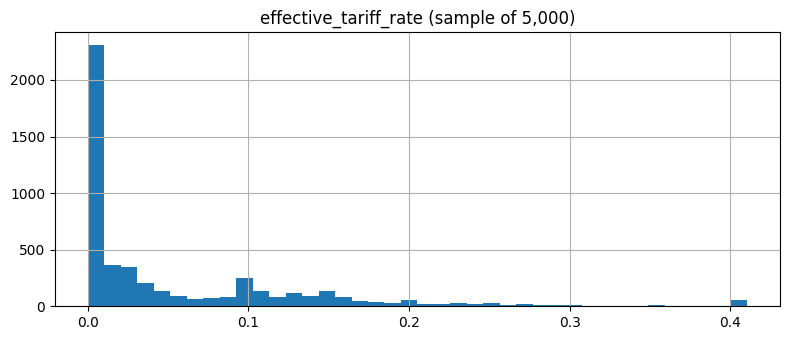

                       effective_tariff_rate  import_value_usd_log
effective_tariff_rate                 1.0000               -0.0356
import_value_usd_log                 -0.0356                1.0000


In [47]:
df["effective_tariff_rate"] = np.where(df["consumption_value_usd"] > 0,
                                       df["calculated_duty_usd"] / df["consumption_value_usd"], 0.0)
FEATURES.append("effective_tariff_rate")
print(df.groupby(df["month"].dt.year).apply(lambda g: g["calculated_duty_usd"].sum() / g["consumption_value_usd"].sum()).rename("value-weighted rate by year"))
show_feature("effective_tariff_rate", clip=(0, 0.99))

**Computed as** calculated duty divided by imports for consumption value for that partner, code and month (0 when nothing entered for consumption, because no duty was assessed).

**Justification.** This is the tariff the importer actually paid as a share of the goods' value, which is the most direct measure of tariff pressure in our data. It rose from about 2.7% in 2024 to 8.8% in 2025 across our three categories. A higher rate raises landed cost, so we expect it to push import value down over time, or to shift purchases to other partners. The histogram shows most rows pay little or nothing (duty-free trade) with a long tail of heavily tariffed flows. (The display is clipped at the 99th percentile so the bulk of the distribution is visible.)

### Feature 2: `tariff_shock_vs_2024` (sophisticated: comparison across time points)

Rows without a 2024 baseline (pair did not trade in 2024): 6,559 (2.4%), left as NaN


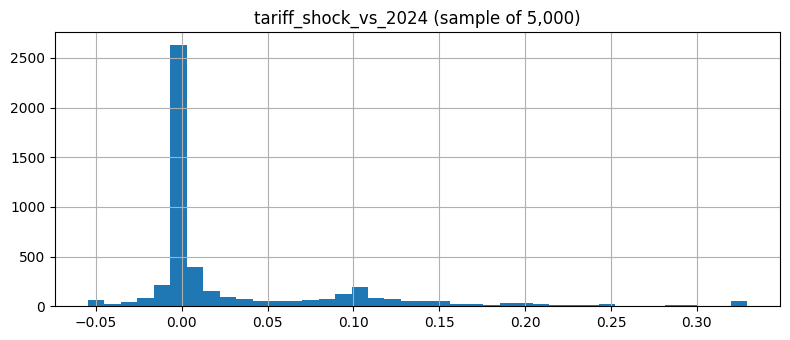

                      tariff_shock_vs_2024  import_value_usd_log
tariff_shock_vs_2024                1.0000               -0.0182
import_value_usd_log               -0.0182                1.0000


In [48]:
base = (df[df["month"].dt.year == 2024].groupby(PAIR)[["calculated_duty_usd", "consumption_value_usd"]].sum())
base_rate = (base["calculated_duty_usd"] / base["consumption_value_usd"].where(base["consumption_value_usd"] > 0)).rename("base_rate_2024")
df = df.merge(base_rate.reset_index(), on=PAIR, how="left")
df["tariff_shock_vs_2024"] = df["effective_tariff_rate"] - df["base_rate_2024"]
df = df.drop(columns="base_rate_2024")
FEATURES.append("tariff_shock_vs_2024")
print(f"Rows without a 2024 baseline (pair did not trade in 2024): {df['tariff_shock_vs_2024'].isna().sum():,} ({df['tariff_shock_vs_2024'].isna().mean():.1%}), left as NaN")
show_feature("tariff_shock_vs_2024", clip=(0.01, 0.99))

**Computed as** this month's effective tariff rate minus the same partner and code's value-weighted effective rate over all of 2024 (the last pre-tariff year).

**Justification.** The absolute rate mixes tariff policy with product mix (some goods always carried high duties). The change against a pair's own 2024 baseline isolates the **new** tariff burden, which is what procurement teams react to. A large positive shock should precede falling imports from that partner, or a surge just before the shock (front-loading). The distribution is concentrated at 0 before 2025 and spreads to the right after. Pairs with no 2024 trade have no baseline and are left as NaN rather than invented.

### Feature 3: `import_price_yoy` (sophisticated: ratio between time points)

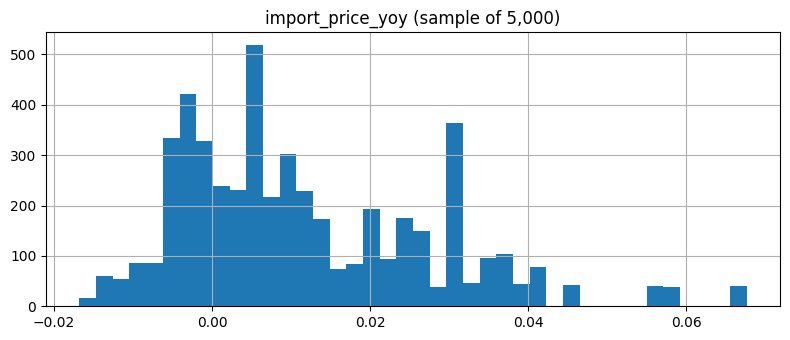

                      import_price_yoy  import_value_usd_log
import_price_yoy                1.0000                0.0399
import_value_usd_log            0.0399                1.0000


In [49]:
price_yoy = series.copy()
price_yoy["month"] = price_yoy["month"].astype(df["month"].dtype)
price_yoy["import_price_yoy"] = price_yoy.groupby("fred_series")["price_interp"].transform(lambda s: s / s.shift(12) - 1)
df = df.merge(price_yoy[["fred_series", "month", "import_price_yoy"]], on=["fred_series", "month"], how="left")
FEATURES.append("import_price_yoy")
show_feature("import_price_yoy")

**Computed as** the category's import price index this month divided by its value 12 months earlier, minus 1 (from the full FRED history, so 2022 rows are covered; October 2025 uses the interpolated value from Part 3).

**Justification.** This splits the price part of our business question from volume: if import value rises while import prices are also rising, part of the rise is just inflation. A year-over-year change removes seasonality and shows whether foreign suppliers raised or cut their prices as tariffs arrived. There are only three series, so the distribution has few distinct values; it is centred near zero with small positive and negative changes.

### Feature 4: `import_value_lag1` (sophisticated: lag feature)

NaN only in the first month (no earlier data): 4,963 rows


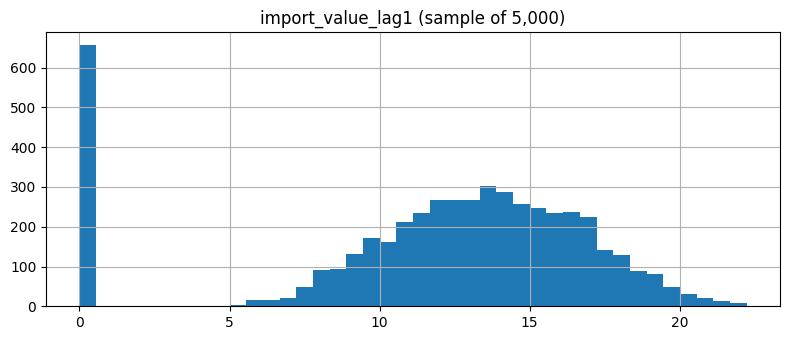

                      import_value_lag1  import_value_usd_log
import_value_lag1                1.0000                0.8134
import_value_usd_log             0.8134                1.0000


In [50]:
p = panel(TARGET)
lag1 = p.shift(1, axis=1)
df = df.merge(to_long(lag1, "import_value_lag1"), on=PAIR + ["month"], how="left")
FEATURES.append("import_value_lag1")
print(f"NaN only in the first month (no earlier data): {df['import_value_lag1'].isna().sum():,} rows")
show_feature("import_value_lag1")

**Computed as** the same partner and code's log import value in the previous calendar month (0 if they did not trade that month).

**Justification.** Trade relationships are persistent: contracts, supply chains and shipping schedules mean last month's flow is the best single guide to this month's. For a procurement team, a forecast that starts from last month is the natural baseline, and departures from it are the tariff effect we want to see. The distribution has a spike at 0 (pairs that did not trade last month) and a bell-shaped body for active relationships, and it correlates strongly with the target.

### Feature 5: `rolling_3m_prior_mean` (sophisticated: rolling window)

NaN in the first 3 months (incomplete window): 15,137 rows


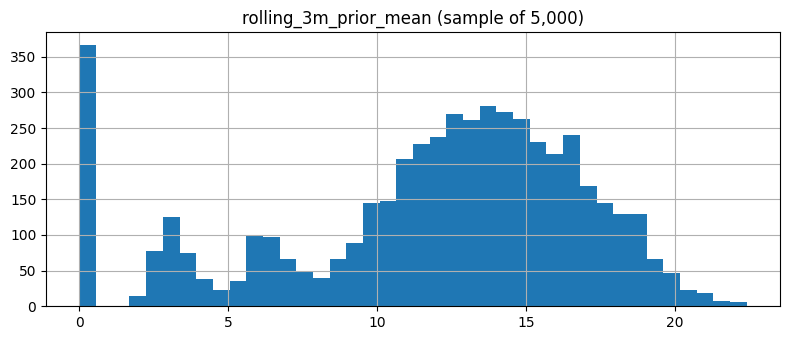

                       rolling_3m_prior_mean  import_value_usd_log
rolling_3m_prior_mean                 1.0000                0.8592
import_value_usd_log                  0.8592                1.0000


In [51]:
roll3 = p.T.shift(1).rolling(3, min_periods=3).mean().T
df = df.merge(to_long(roll3, "rolling_3m_prior_mean"), on=PAIR + ["month"], how="left")
FEATURES.append("rolling_3m_prior_mean")
print(f"NaN in the first 3 months (incomplete window): {df['rolling_3m_prior_mean'].isna().sum():,} rows")
show_feature("rolling_3m_prior_mean")

**Computed as** the average log import value of the same partner and code over the **three months before** this one (the current month is excluded, so the feature never uses the value it is trying to explain).

**Justification.** One month can be noisy (a single large shipment, a holiday). A three-month average gives the recent normal level of a trade relationship. When the current month sits far above it just before a tariff date, that is front-loading; far below it afterwards is the tariff cutting into imports. Its distribution is smoother than the one-month lag, with fewer exact zeros.

### Feature 6: `supplier_share_lag1`

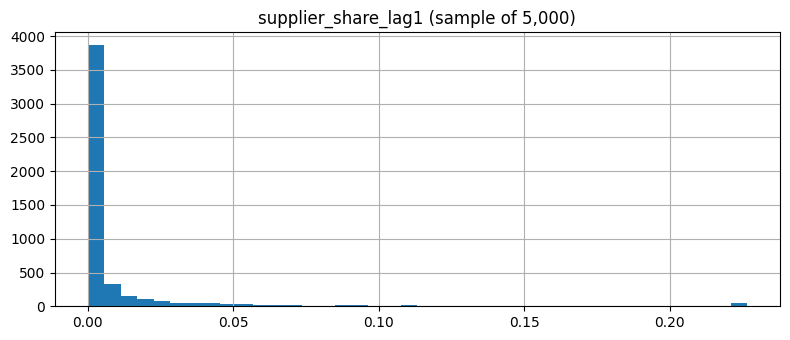

                      supplier_share_lag1  import_value_usd_log
supplier_share_lag1                1.0000                0.4214
import_value_usd_log               0.4214                1.0000


In [52]:
totals = df.groupby(["enduse_code", "month"])["import_value_usd"].transform("sum")
df["_share"] = np.where(totals > 0, df["import_value_usd"] / totals, 0.0)
share_lag = panel("_share").shift(1, axis=1)
df = df.merge(to_long(share_lag, "supplier_share_lag1"), on=PAIR + ["month"], how="left").drop(columns="_share")
FEATURES.append("supplier_share_lag1")
show_feature("supplier_share_lag1", clip=(0, 0.99))

**Computed as** the partner's share of all US imports of that end-use code in the **previous** month (lagged so it does not contain the current target).

**Justification.** It measures how dependent US buyers are on that supplier. A partner holding 60% of a product cannot be replaced quickly, so its imports should hold up even under a tariff, while small suppliers are easy to switch away from. That makes share a direct input to the stakeholder's sourcing decision. Most partners hold a tiny share of any product, so the distribution is concentrated near 0 with a long tail of dominant suppliers.

### Feature 7: `post_tariff_period`

post_tariff_period
0   0.0238
1   0.1334
Name: mean effective tariff rate, dtype: float64


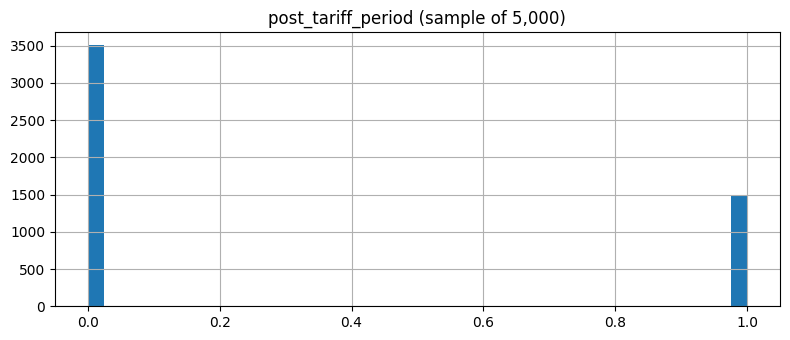

                      post_tariff_period  import_value_usd_log
post_tariff_period                1.0000               -0.0026
import_value_usd_log             -0.0026                1.0000


In [53]:
df["post_tariff_period"] = (df["month"] >= "2025-04-01").astype(int)
FEATURES.append("post_tariff_period")
print(df.groupby("post_tariff_period")["effective_tariff_rate"].mean().rename("mean effective tariff rate"))
show_feature("post_tariff_period")

**Computed as** 1 for months from April 2025 onward, 0 before. This is a simple date extraction, so here is why this specific cut-off matters: April 2025 is when the broad baseline tariff on nearly all trading partners took effect, which turns the tariff regime from targeted (earlier steel, aluminum and China measures) to economy-wide. The mean effective rate printed above confirms the regime change in our own data.

**Justification.** It lets later models estimate the average shift in import value under the new regime, controlling for everything else. Its distribution is two bars (pre and post).

In [54]:
feature_summary = pd.DataFrame({
    "corr with target": [df[[f, TARGET]].corr().iloc[0, 1] for f in FEATURES],
    "non-null rows": [int(df[f].notna().sum()) for f in FEATURES],
    "type": ["domain", "domain + sophisticated (time comparison)", "domain + sophisticated (ratio between time points)",
             "sophisticated (lag)", "sophisticated (rolling window)", "domain", "domain (justified date extraction)"],
}, index=FEATURES)
for f in FEATURES:
    LOG.append(dict(column=f, problem="New feature", action="Engineered (Part 6)", before="did not exist",
                    after=f"{int(df[f].notna().sum()):,} values; corr {df[[f, TARGET]].corr().iloc[0,1]:.3f}", member=MEMBER["part6"]))
feature_summary

,corr with target,non-null rows,type
effective_tariff_rate,-0.0356,277592,domain
tariff_shock_vs_2024,-0.0182,271033,domain + sophisticated (time comparison)
import_price_yoy,0.0399,277592,domain + sophisticated (ratio between time poi...
import_value_lag1,0.8134,272629,sophisticated (lag)
rolling_3m_prior_mean,0.8592,262455,sophisticated (rolling window)
supplier_share_lag1,0.4214,272629,domain
post_tariff_period,-0.0026,277592,domain (justified date extraction)


**Reading the correlations.** The two lag features correlate strongly with the target (0.81 and 0.86): trade relationships are persistent. Supplier share is moderately correlated (0.42): dominant suppliers ship larger flows. The tariff features are close to 0 in a straight pooled correlation, and that is expected rather than a sign they are useless. Across 277k rows the target varies mostly with **who** the partner is (Mexico versus Fiji), and a tariff acts **over time within** a partner and product. Those effects show up once the model compares a pair with its own history, which is exactly what the lag and rolling features let Project 2 do. Pearson also only captures straight-line relationships, while a tariff shock is expected to produce a spike (front-loading) followed by a drop.

---
# Part 7: Cleaning Log and Individual Contributions

## 7.1 Cleaning log
The log below is written to `cleaning_log.md` in the repository root from the steps recorded above, so its numbers always match this notebook.

In [55]:
summary = {
    "rows before": d2_start_rows, "rows after": len(df),
    "columns before": d2_start_cols, "columns after": df.shape[1],
    "missing before": d2_start_missing, "missing after": int(df.isna().sum().sum()),
    "new features": len(FEATURES),
}
lines = ["# Cleaning Log: Deliverable 2 (Group 5, Domain D)", "",
         "| Column | Problem found | Action taken | Statistic before | Statistic after | Handled by |",
         "|---|---|---|---|---|---|"]
for e in LOG:
    lines.append(f"| {e['column']} | {e['problem']} | {e['action']} | {e['before']} | {e['after']} | {e['member']} |")
lines.append(f"| **DATASET SUMMARY** | Rows before: {summary['rows before']:,}; rows after: {summary['rows after']:,} | "
             f"Columns before: {summary['columns before']}; columns after: {summary['columns after']} | "
             f"Missing values before: {summary['missing before']:,} | Missing values after: {summary['missing after']:,} "
             f"(feature NaNs where no earlier data exists; every imputed column is 0) | New features added: {summary['new features']} |")
with open("cleaning_log.md", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print("\n".join(lines))

# Cleaning Log: Deliverable 2 (Group 5, Domain D)

| Column | Problem found | Action taken | Statistic before | Statistic after | Handled by |
|---|---|---|---|---|---|
| 9 Census value and weight columns | Numbers stored as text (object dtype) | pd.to_numeric to int64 | dtype object; text max = 99999 | dtype int64; max = 52,665,639,215 | Janek Basi |
| month | Date stored as text YYYY-MM-01 | pd.to_datetime; dropped duplicate text column census_time | dtype object | dtype datetime64 | Janek Basi |
| country | Upper-case text, untrimmed | .str.strip().str.title() | top: TOTAL FOR ALL COUNTRIES | top: Total For All Countries | Janek Basi |
| enduse_desc | Upper-case text, untrimmed | .str.strip().str.title() | top: ARTWORK, ANTIQUES, STAMPS, ETC. | top: Artwork, Antiques, Stamps, Etc. | Janek Basi |
| (all rows) | Possible duplicate rows | drop_duplicates on cty_code + enduse_code + month | 0 duplicates | 0 duplicates | Janek Basi |
| cty_code | All-country total row labelled DET (doubl

In [56]:
pd.Series(summary, name="value").to_frame()

,value
rows before,453105
rows after,277592
columns before,21
columns after,46
missing before,8833
missing after,31622
new features,7


## 7.2 Individual Contributions

**Commit history** (repo, then Commits; replace with a current screenshot before submitting):

`PASTE COMMIT HISTORY SCREENSHOT HERE`

**Janek Basi:** EDIT so it matches the commit history. Suggested: Part 1 (re-pulled data validation, corrected join, column annotation) and Part 2 (general cleaning and domain problems D1 to D6).

**Priyanshu Batra:** EDIT so it matches the commit history. Suggested: Census API pull and data-v2 release, Part 3 (missingness diagnosis and imputation) and Part 4 (outlier detection and handling).

**Jashanpreet Singh:** EDIT so it matches the commit history. Suggested: Part 5 (skewness, transformation, scaling), Part 6 (feature engineering) and the cleaning log.